# [58기-데타출동] 데이터 시각화 프로젝트

## Steam 게임 특성별 게임 가격과 플레이타임 간의 관계
### <2주차> 데이터 분석

### #00 분석 개요

2025년 3월 Steam 게임의 특성(장르, DLC 유무, 도전과제 수)에 따라 가격대별 플레이타임에 어떠한 차이가 나타나는지 비교·분석한다.

**질문**:
- Q1. 어느 가격대의 게임에서 플레이타임이 가장 길게 나타나는가?
    - 가격대별로 플레이타임 차이가 있는가? 
- Q2. 게임의 특성(장르, DLC 유무, 도전과제 수)에 따라 가격대별 플레이타임 차이가 나타나는가?
    - 장르에 따라 가격대별 플레이타임 차이가 있는가? 
    - DLC 유무에 따라 가격대별 플레이타임 차이가 나타나는가? 
    - 도전과제 구간에 따라 가격대별 플레이타임 차이가 나타나는가? 

### #01 데이터 분석

#### 0. 분석 준비

In [2]:
# 라이브러리 불러오기
from pandas import read_csv, melt, pivot_table
import pandas as pd
import numpy as np
from helpers import *

In [3]:
# 데이터 불러오기
origin = read_csv('steam_clean.csv')
origin.head()

,appid,name,가격대,도전과제,DLC,Indie,Action,Adventure,Casual,Simulation,RPG,Strategy,Sports,Racing,기타,median_playtime
0,730,Counter-Strike 2,무료,1~20개,있음,0,1,0,0,0,0,0,0,0,0,5174
1,570,Dota 2,무료,0개,있음,0,1,0,0,0,0,1,0,0,0,898
2,271590,Grand Theft Auto V Legacy,무료,41개 이상,없음,0,1,1,0,0,0,0,0,0,0,7101
3,359550,Tom Clancy's Rainbow Six® Siege,0달러 초과~5달러 미만,0개,있음,0,1,0,0,0,0,0,0,0,0,2434
4,252490,Rust,20달러 이상,41개 이상,있음,1,1,1,0,0,1,0,0,0,0,3675


#### Q1. 가격대별로 플레이타임 차이가 있는가? 

가격대별 플레이타임의 기술통계량을 확인한다.

In [4]:
order = ['무료',
         '0달러 초과~5달러 미만',
         '5~10달러 미만',
         '10~20달러 미만',
         '20달러 이상']

origin.groupby(['가격대'])['median_playtime'].agg(
    count='count',
    median='median',
    mean='mean',
    iqr=lambda x: x.quantile(.75) - x.quantile(.25)
).round(2).reindex(order, level='가격대')

,count,median,mean,iqr
가격대,,,,
무료,1040,51.0,402.51,154.25
0달러 초과~5달러 미만,2241,191.0,2524.63,235.00
5~10달러 미만,1522,197.0,468.19,326.75
10~20달러 미만,2081,269.0,605.27,499.00
20달러 이상,1126,522.5,1985.56,970.00


가격대 구간별 플레이타임 중앙값 분포가 얼마나 겹치는지 확인한다.

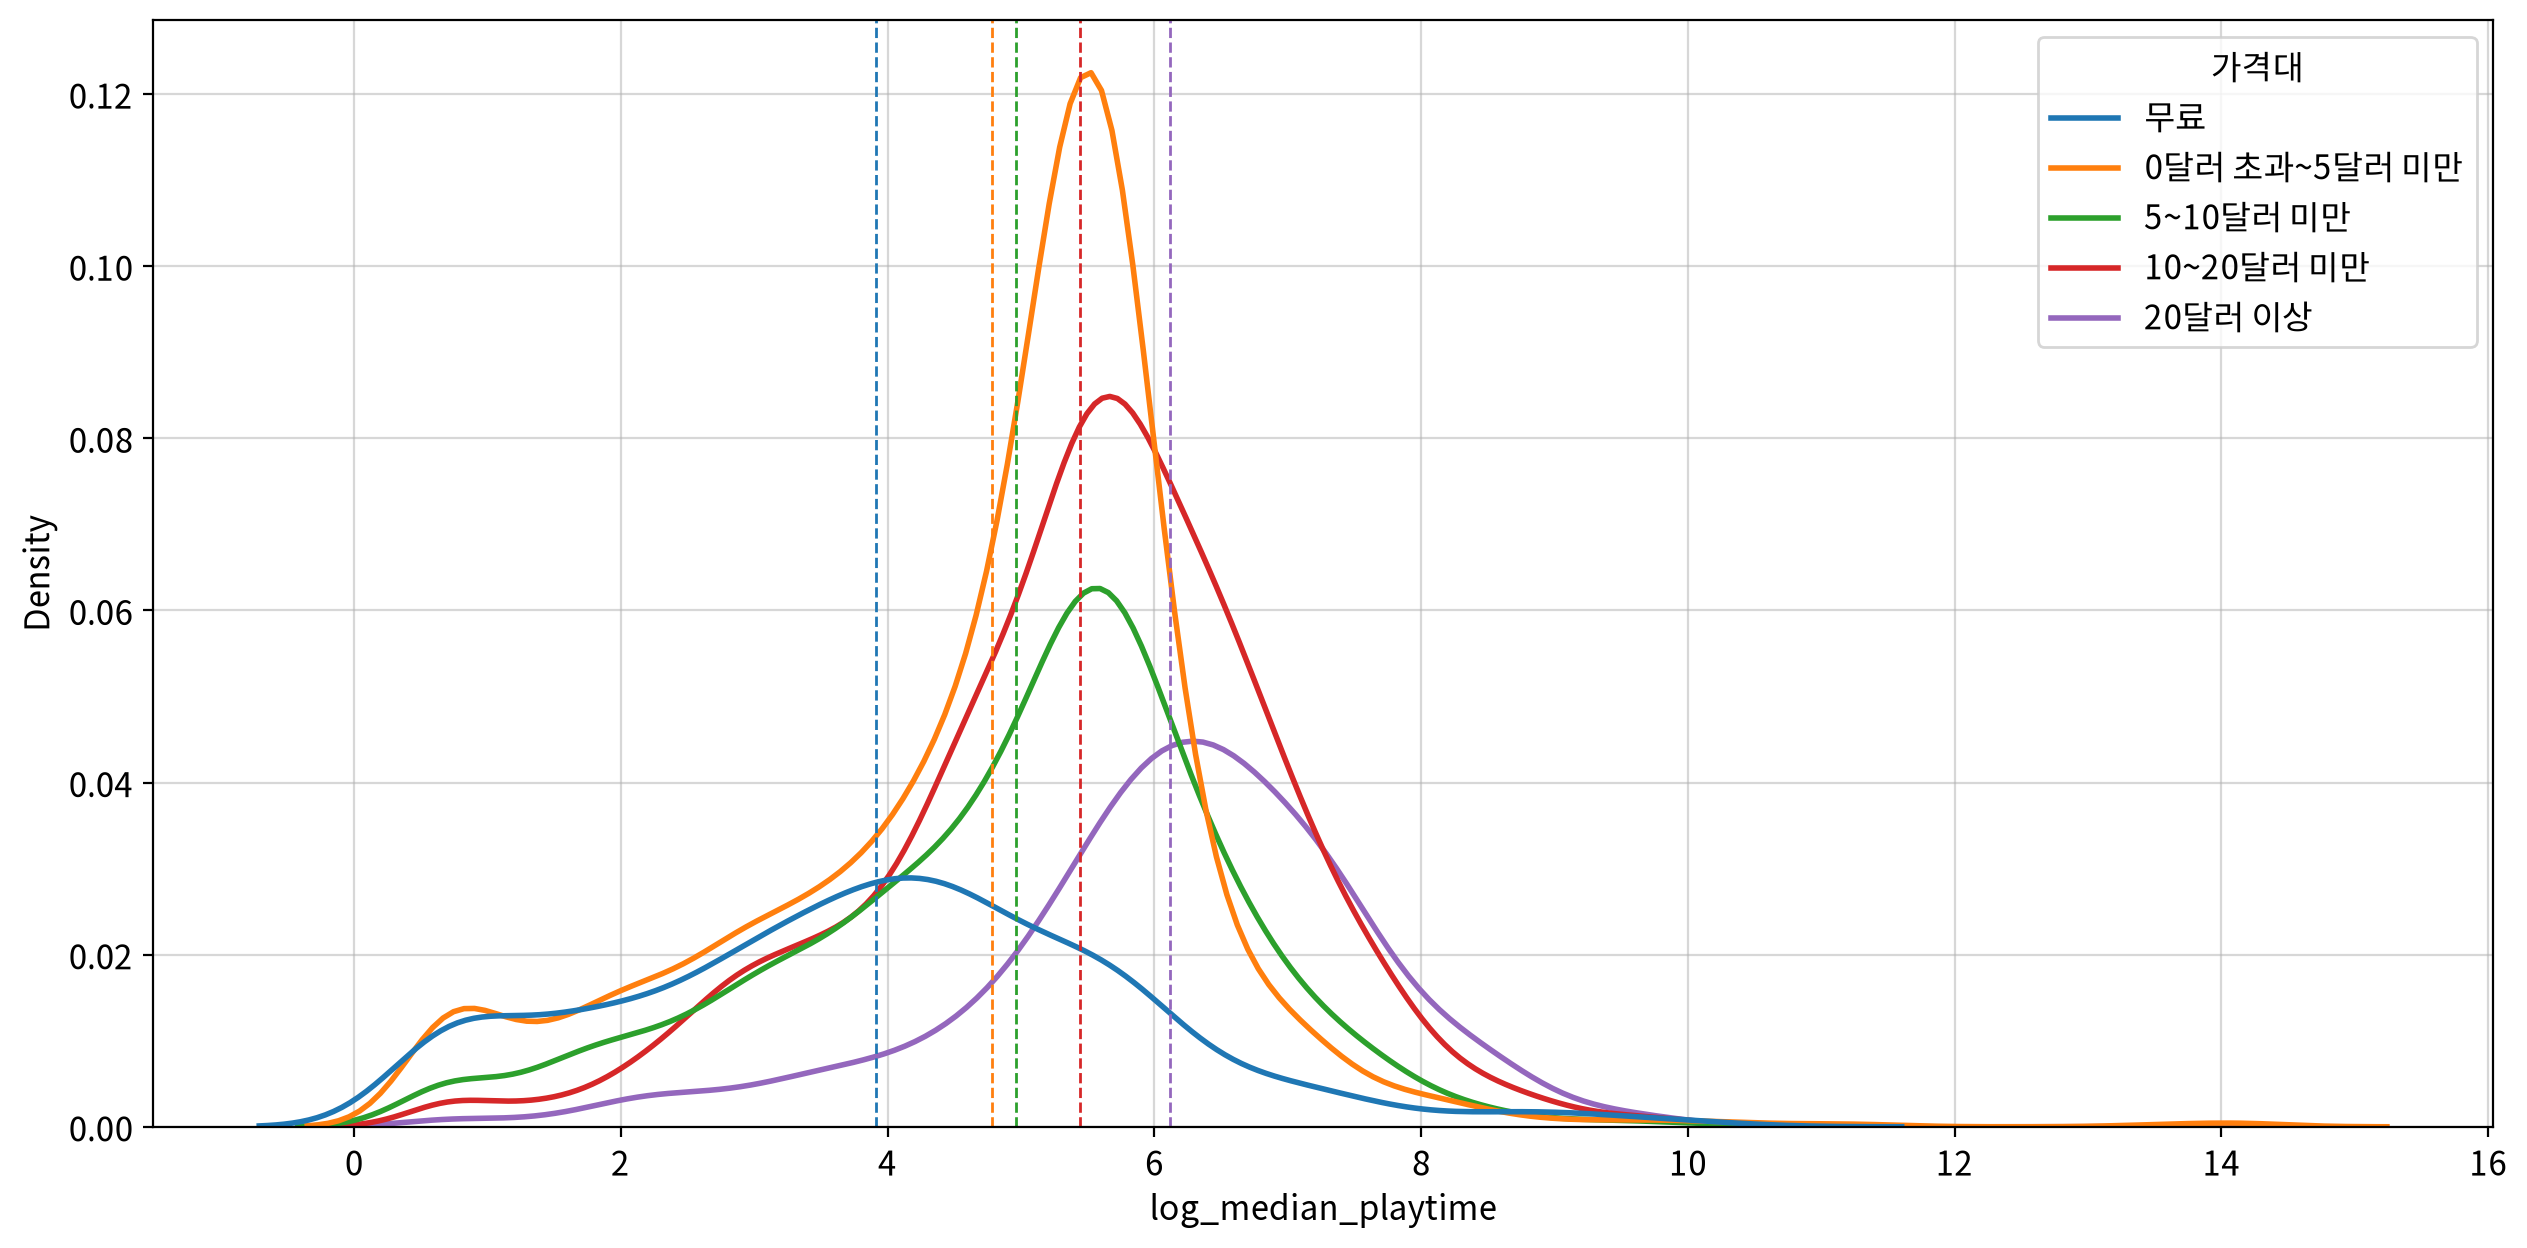

,log_median_playtime
가격대,
무료,3.92
0달러 초과~5달러 미만,4.78
5~10달러 미만,4.96
10~20달러 미만,5.44
20달러 이상,6.11


In [31]:
origin['log_median_playtime'] = np.log1p(origin['median_playtime'])

my_plot.kdeplot(
    origin,
    x='log_median_playtime',
    hue='가격대',
    hue_order=order,
    meanline=True
)

origin[['log_median_playtime', '가격대']].groupby('가격대').mean().reindex(order).round(2)

> 가격대별 로그 변환된 플레이타임 중앙값의 평균은 무료 3.92에서 20달러 이상 6.11까지 가격대가 높아질수록 증가하는 경향을 보였다.   
> 그러나 다섯 가격대의 밀도 곡선이 로그 플레이타임 2~8 구간에서 넓게 겹쳐, 서로 다른 가격대에서도 비슷한 플레이타임을 기록하는 게임이 존재함을 확인하였다.

박스플롯을 활용하여 평균보다 극단값의 영향을 적게 받는 중앙값을 중심으로 가격대별 플레이타임 중앙값, IQR, 이상치를 확인하고 분포의 차이를 살펴보고자 한다.

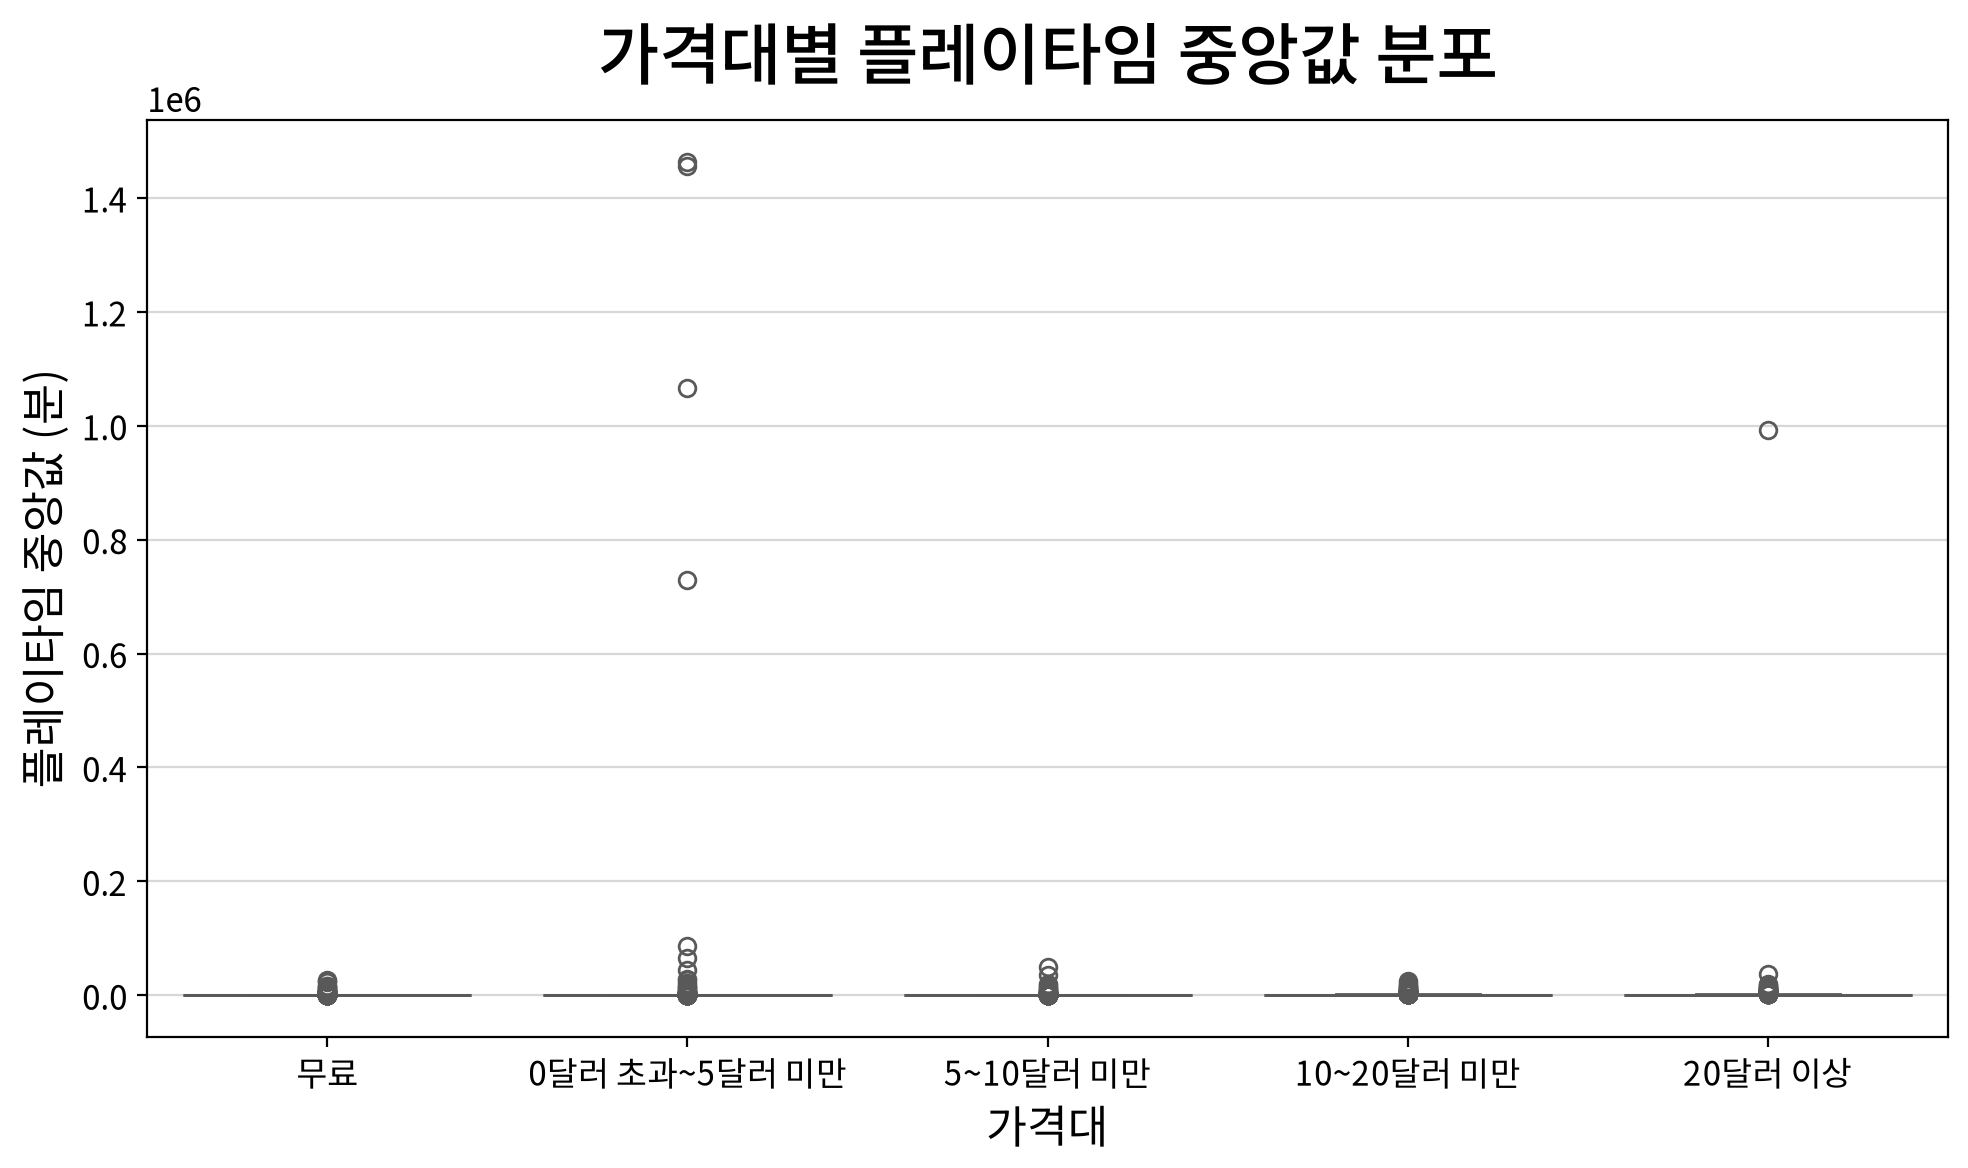

In [6]:
# 전처리된 데이터로 가격대별 플레이타임 중앙값 분포 시각화
my_plot.boxplot(
    data=origin,
    x='가격대',
    y='median_playtime',
    order=order,
    palette='Set2',
    width=1000,
    height=600,
    title='가격대별 플레이타임 중앙값 분포',
    xlabel='가격대',
    ylabel='플레이타임 중앙값 (분)'
)

- 가격대별 플레이타임 중앙값을 박스플롯으로 시각화한 결과, 일부 게임에서 매우 큰 이상치가 관찰되었다.
- 특히 0달러 초과~5달러 미만 가격대에서 극단적으로 높은 플레이타임 중앙값이 나타났다.
> 전체 그래프의 세로축 범위가 크게 확장되어 대부분의 게임이 그래프 하단에 밀집되어 가격대별 중앙값, IQR, 분포 차이를 시각적으로 비교하기 어렵다.

원본 데이터의 값을 유지하면서 극단적으로 큰 값으로 인한 시각적 왜곡을 완화하기 위해 세로축에 로그 눈금을 적용하고자 한다.

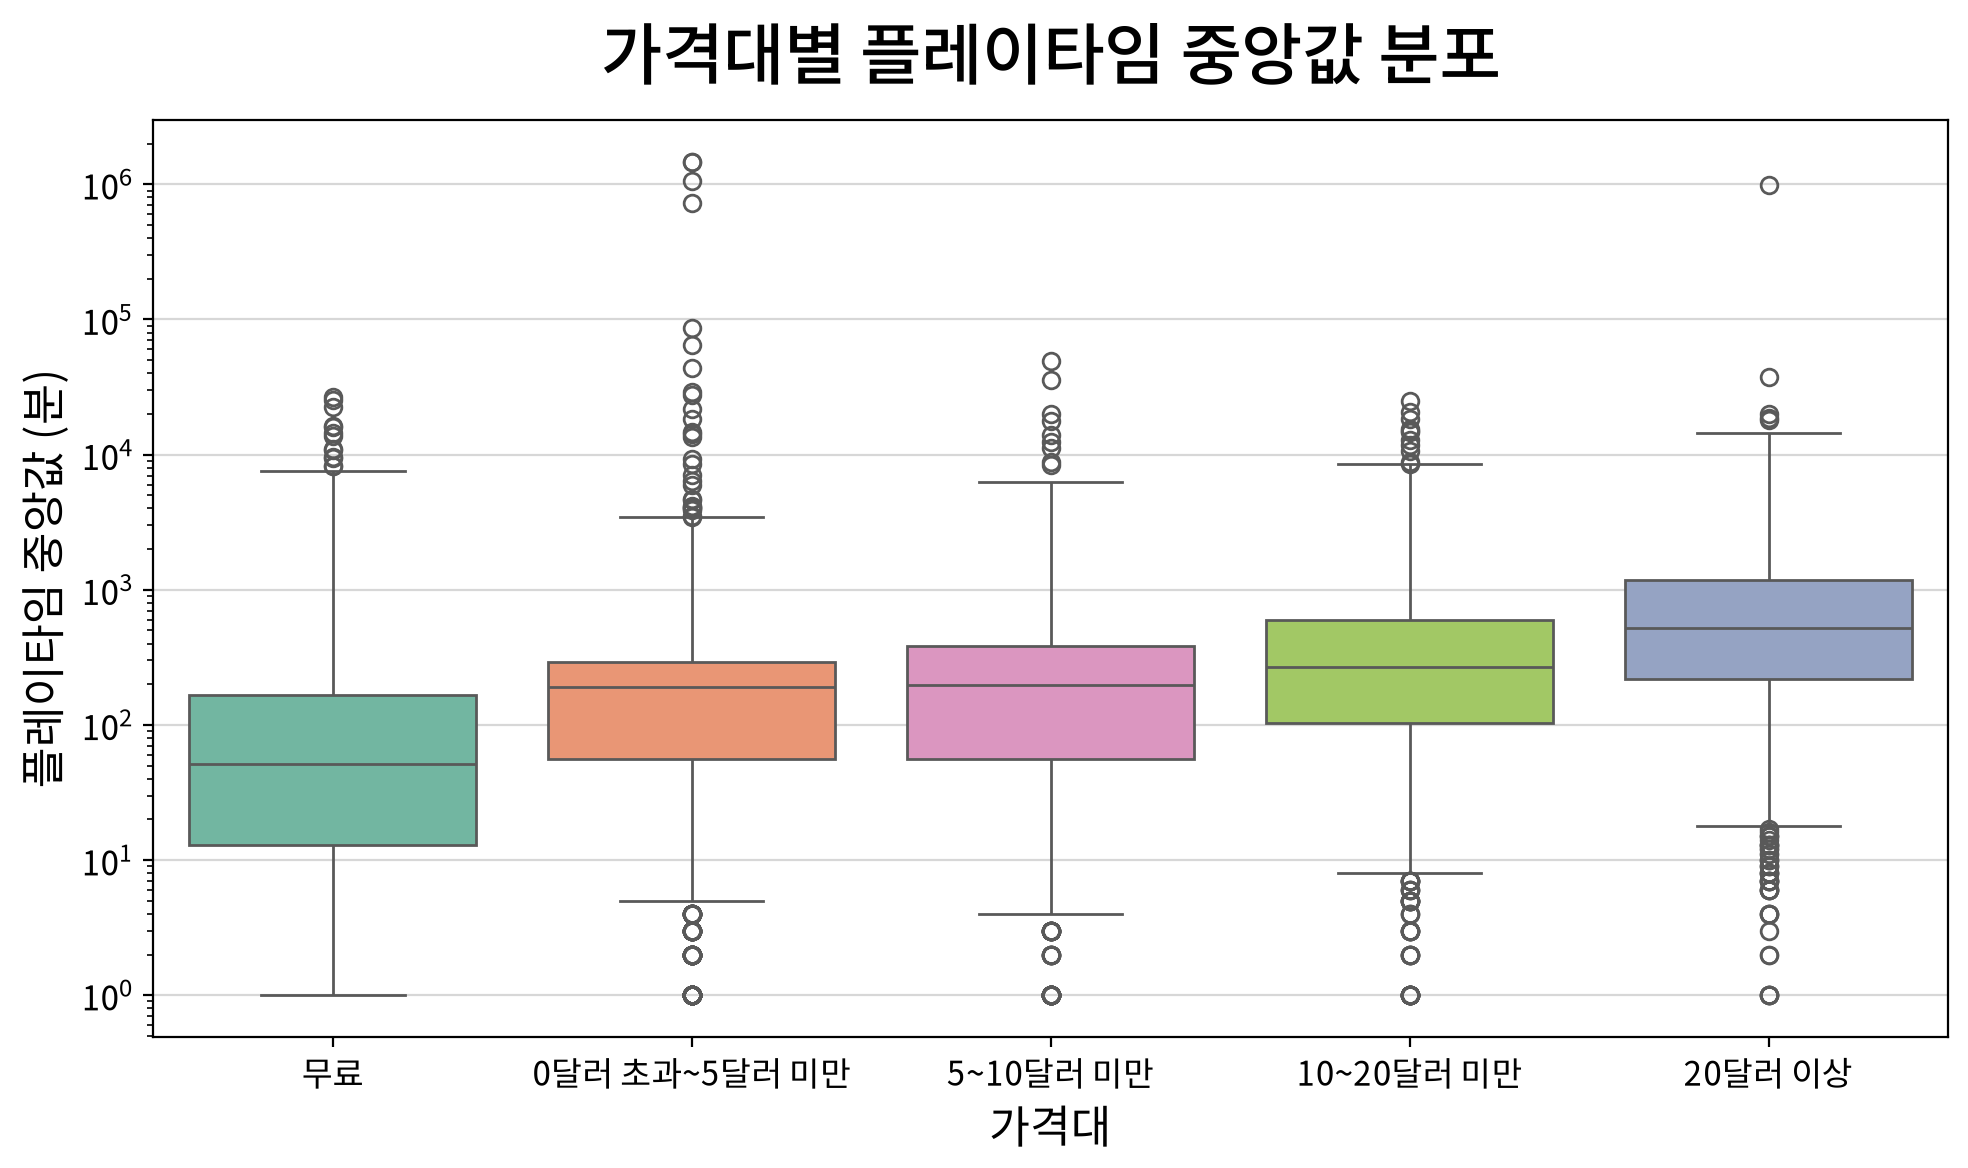

In [7]:
# 박스 플롯 그리기
my_plot.boxplot(data=origin, x='가격대', y='median_playtime', order=order, palette='Set2',
                log_scale=True, width=1000, height=600,
                title='가격대별 플레이타임 중앙값 분포', xlabel='가격대', ylabel='플레이타임 중앙값 (분)')

- 로그 눈금을 적용하고 가격대별 중앙값과 IQR이 명확하게 구분되었다.
- 이상치 값이 지나치게 많아 일부 구간에서 점이 겹쳐 보인다.

> 다만 Q1은 개별 이상치를 탐색하는 것이 아니라 가격대별 플레이타임 중앙값 분포를 비교하는 것이므로 그래프에서 이상치를 숨김 처리한다.

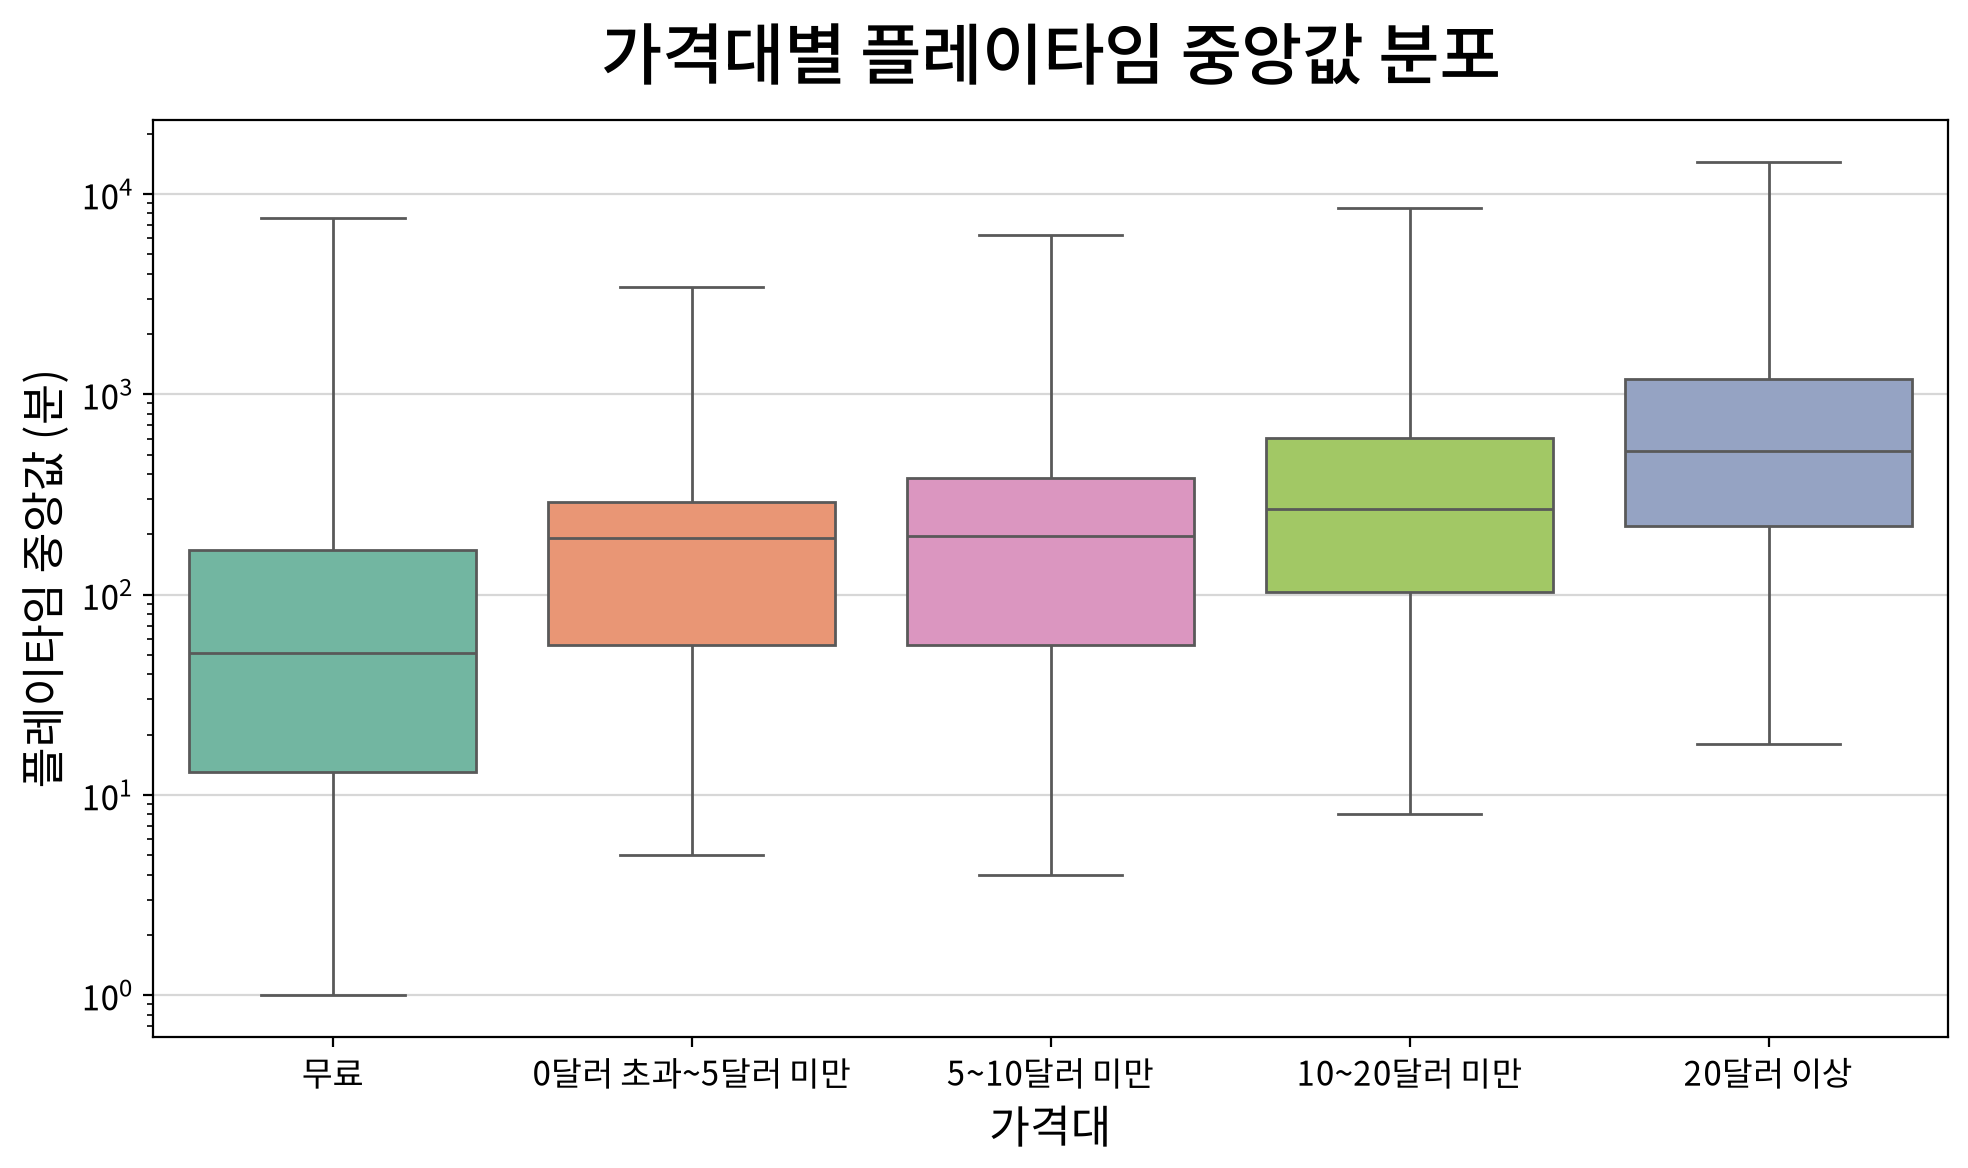

In [8]:
# 박스플롯 이상치 표시 숨김
my_plot.boxplot(data=origin, x='가격대', y='median_playtime', order=order, palette='Set2',
                showfliers=False, log_scale=True, width=1000, height=600,
                title='가격대별 플레이타임 중앙값 분포', xlabel='가격대', ylabel='플레이타임 중앙값 (분)')

> **1. 가격대 상승에 따른 플레이타임 중앙값 증가 경향**
> - Steam 인기 게임 8,010개를 분석한 결과, 가격대가 높아질수록 게임별 플레이타임 중앙값이 대체로 증가하는 경향이 관찰되었다.
> - `무료` 게임의 플레이타임 중앙값은 51분인 반면, 20달러 이상 게임은 522.5분으로 약 10.25배 높게 나타났다.
> - `0달러 초과~5달러 미만`과 `5~10달러 미만` 구간의 중앙값 차이는 6분에 불과하여, 가격 상승에 비례해 플레이타임 중앙값이 일관되게 증가한다고 보기는 어렵다.
> - 모든 가격대에서 플레이타임 중앙값의 분포 범위가 넓게 나타나 동일한 가격대 내에서도 게임별 플레이타임 중앙값 차이가 큰 것으로 확인되었다.
> - 따라서 가격대별 중앙값은 각 집단의 대표적인 경향을 비교하는 데 유용하지만, 개별 게임의 플레이타임 중앙값 차이까지 충분히 설명하지는 못한다는 한계가 있다.
> 
> **2. 선행연구와의 비교를 통한 분석 결과 뒷받침**
> - 선행연구에서도 본 프로젝트에서 관찰된 가격대와 플레이타임 중앙값 사이의 양의 관계와 유사한 결과가 확인되었다.
> - **Bailey(2020)** 는 20~59.99달러 게임의 플레이타임 중앙값이 5.8시간으로, 전체 표본의 2.8시간보다 통계적으로 유의하게 높음을 확인하였다.
> - **Ebbing과 Lüthje(2021)** 는 Steam 게임 4,239개의 상관관계 분석에서 게임 가격과 플레이타임 중앙값 사이에 통계적으로 유의한 양의 상관관계(r = 0.22, p < 0.01) 가 있음을 확인하였다.
> 
> **3. 가격과 플레이타임 중앙값 관계의 해석 및 후속 분석 방향**
> - 본 프로젝트와 선행연구에서 가격과 플레이타임 중앙값 사이의 관련성이 관찰되었지만, 게임 가격 자체가 플레이타임 중앙값을 증가시킨다고 단정할 수는 없다.
> - 고가 게임에 특정 장르나 콘텐츠 규모가 큰 작품이 많이 포함되어 있을 가능성도 있으므로, 후속 분석에서는 장르, DLC 개수, 출시연도 등 게임의 특성을 함께 고려하여 가격대별 플레이타임 중앙값 차이가 유지되는지 확인할 필요가 있다.

#### Q2-1. 장르에 따라 가격대별 플레이타임 차이가 있는가?

In [9]:
# 가격대와 장르, 플레이타임 중앙값을 value로 한 테이블 생성
df = melt(origin, id_vars=['가격대', 'median_playtime'],
    value_vars=['Indie', 'Action', 'Adventure', 'Casual', 'Simulation',
    'RPG', 'Strategy', 'Sports', 'Racing', '기타'],
    var_name='장르', value_name='장르여부')

df1 = df.query('장르여부 == 1').drop(columns='장르여부')

df1

,가격대,median_playtime,장르
4,20달러 이상,3675,Indie
5,5~10달러 미만,1173,Indie
9,10~20달러 미만,2053,Indie
13,10~20달러 미만,927,Indie
16,10~20달러 미만,821,Indie
...,...,...,...
80057,무료,1,기타
80058,무료,15,기타
80064,무료,1,기타
80078,무료,1,기타


가격대 × 장르별 플레이타임의 기술통계량을 확인한다.

In [10]:
df1.groupby(['장르', '가격대'])['median_playtime'].agg(
    count='count',
    median='median',
    iqr=lambda x: x.quantile(.75) - x.quantile(.25)
).round(2).reindex(order, level='가격대')

count  median       iqr
장르         가격대                                   
Action     무료               443    55.0    131.00
           0달러 초과~5달러 미만    982   199.0    230.75
           5~10달러 미만        643   182.0    294.50
           10~20달러 미만       962   238.0    438.50
           20달러 이상          613   485.0    810.00
Adventure  무료               333    55.0    143.00
           0달러 초과~5달러 미만    927   198.0    236.00
           5~10달러 미만        644   203.0    282.75
           10~20달러 미만      1013   287.0    501.00
           20달러 이상          461   522.0    810.00
Casual     무료               355    46.0    171.00
           0달러 초과~5달러 미만   1042   170.5    233.50
           5~10달러 미만        503   207.0    314.50
           10~20달러 미만       474   227.0    431.50
           20달러 이상          120   347.5    716.00
Indie      무료               634    45.0    111.75
           0달러 초과~5달러 미만   1731   193.0    223.00
           5~10달러 미만       1064   201.0    301.50
           10~20달러 미만      1420   243.0    447.00
           20달러 이상          414   418.0    706.00
RPG        무료               234    96.5    224.50
           0달러 초과~5달러 미만    372   214.0    240.50
           5~10달러 미만        325   294.0    473.00
           10~20달러 미만       602   347.0    619.00
           20달러 이상          336   853.5   1330.50
Racing     무료                27    26.0     46.00
           0달러 초과~5달러 미만     83   134.0    250.00
           5~10달러 미만         56   179.0    286.75
           10~20달러 미만        80   188.0    310.50
           20달러 이상           47   295.0    614.00
Simulation 무료               213    46.0    145.00
           0달러 초과~5달러 미만    439   187.0    267.00
           5~10달러 미만        363   251.0    468.50
           10~20달러 미만       612   290.0    612.00
           20달러 이상          299   576.0   1000.00
Sports     무료                63    56.0    428.50
           0달러 초과~5달러 미만     66   210.0    266.50
           5~10달러 미만         71   133.0    296.50
           10~20달러 미만       104   125.5    291.25
           20달러 이상           51   308.0    607.00
Strategy   무료               255    80.0    214.00
           0달러 초과~5달러 미만    395   222.0    270.00
           5~10달러 미만        343   244.0    461.00
           10~20달러 미만       494   355.5    627.50
           20달러 이상          303   595.0   1304.50
기타         무료                48    13.0     60.75
           0달러 초과~5달러 미만      3  1282.0  14577.00
           5~10달러 미만         16    90.0    722.50
           10~20달러 미만        14   302.5    460.25
           20달러 이상           16   146.0    878.50

> 장르별 가격대에 따른 플레이타임 중앙값의 차이를 직관적으로 비교하기 위해 히트맵을 활용하고자 한다.

In [11]:
# Heatmap을 그리기 위해 Dataframe 재구성
HD = df1.pivot_table(index='장르', columns='가격대',
                    values='median_playtime', aggfunc='median',
)
HD = HD.reindex(columns=order)
HD.drop(index='기타', inplace=True)

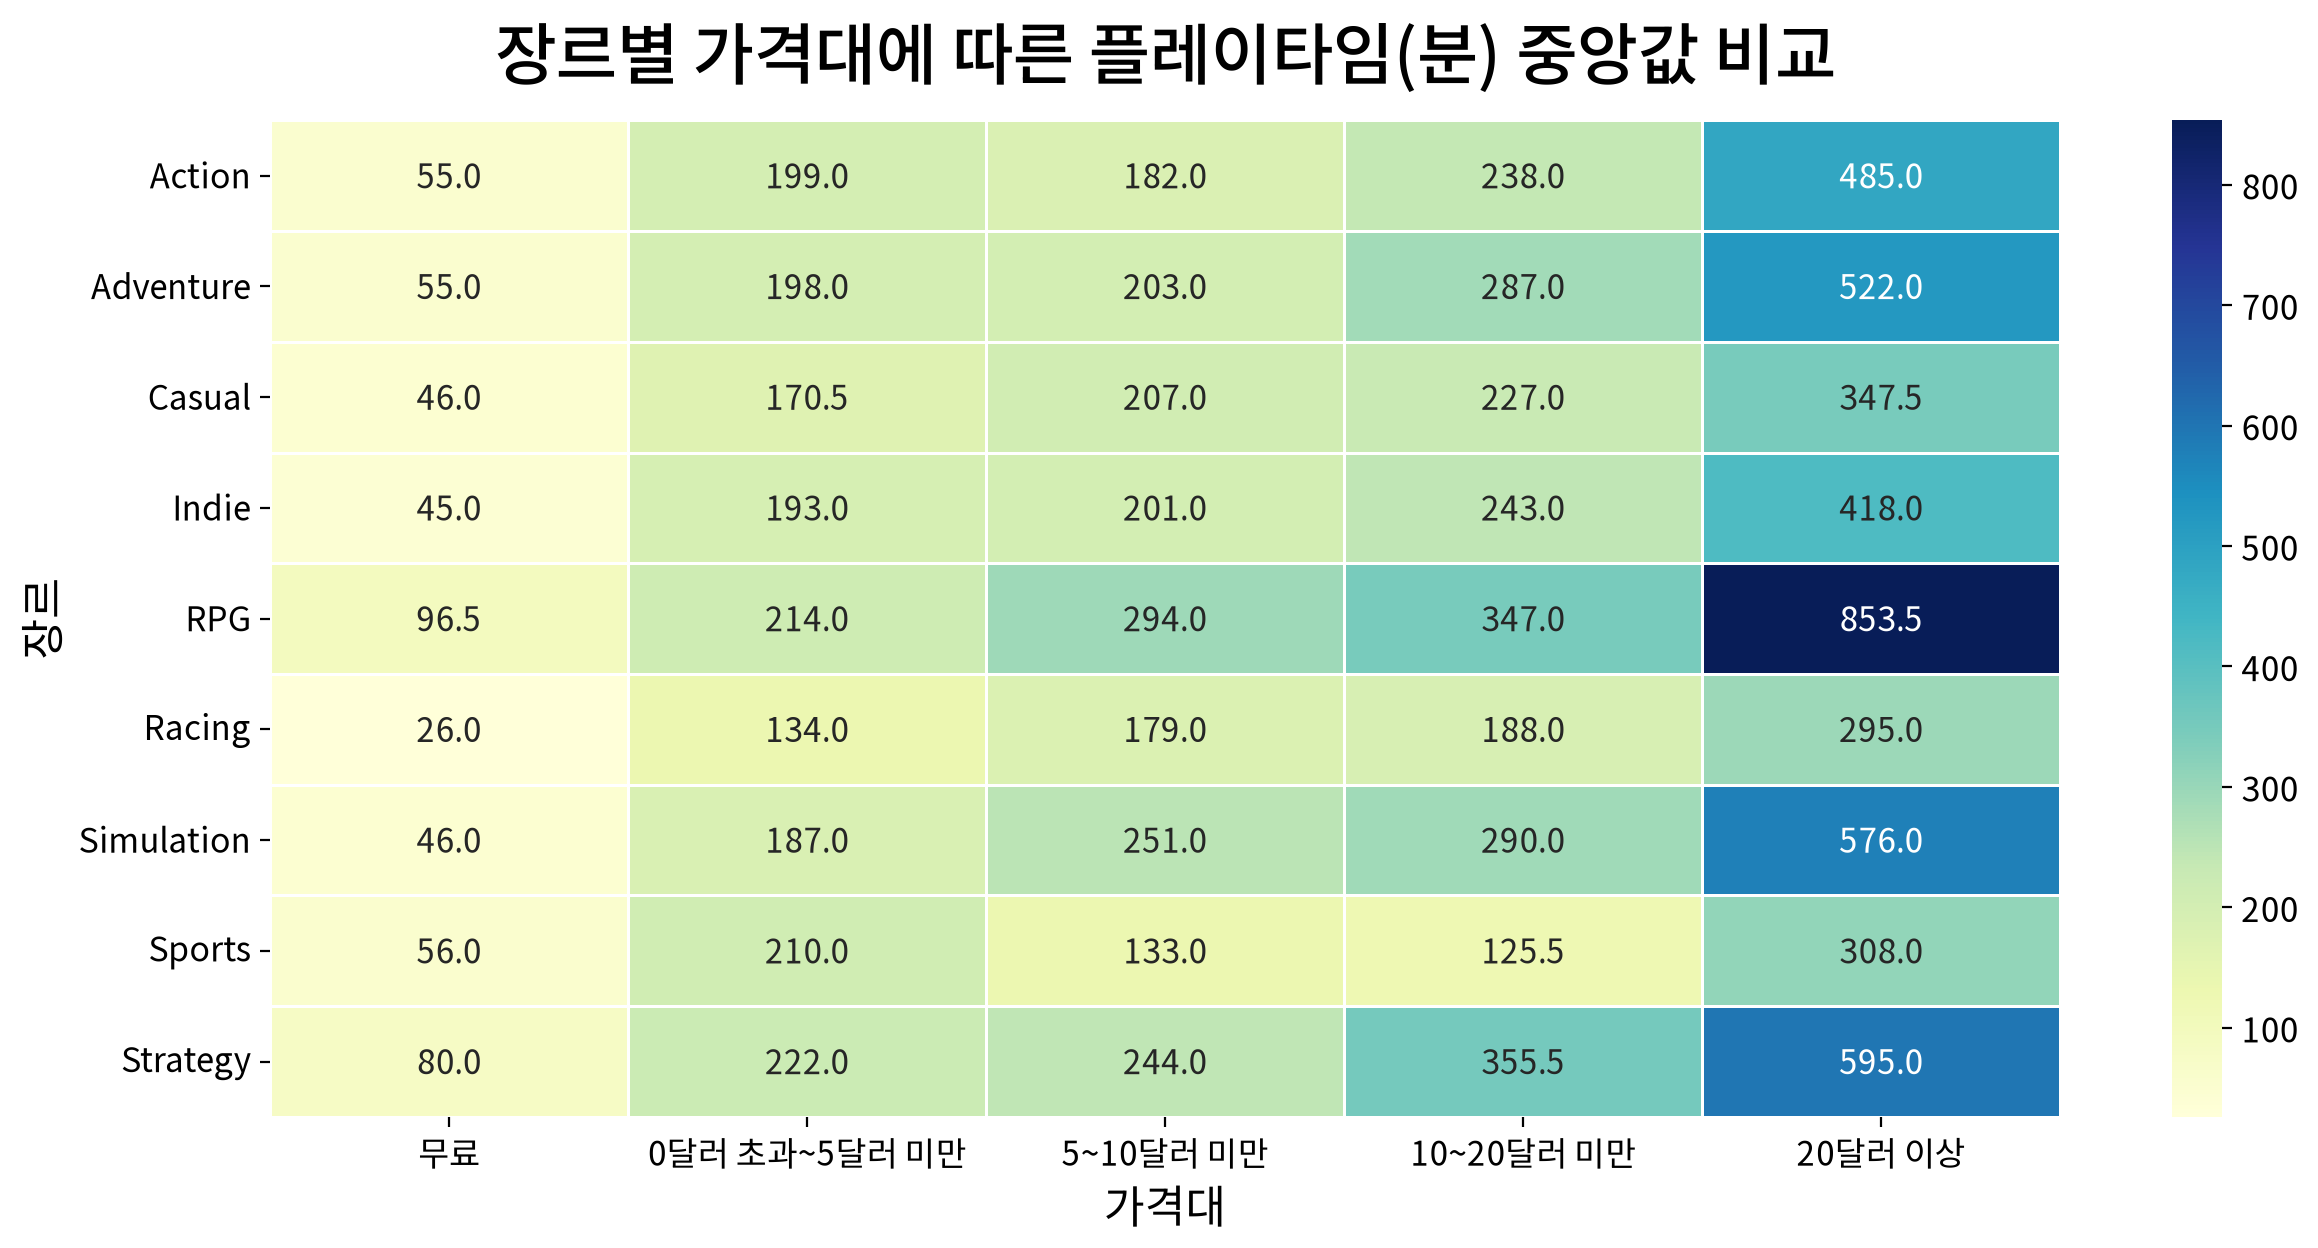

In [12]:
# 히트맵 그리기
my_plot.heatmap(data=HD, fmt='', palette='YlGnBu',
                title='장르별 가격대에 따른 플레이타임(분) 중앙값 비교',
                xlabel='가격대', ylabel='장르')

> **1. 무료 -> 20달러 이상은 9개 장르 모두 증가, 중간 구간의 흐름은 장르마다 다름**
> 
> - `기타`를 제외한 9개 장르 모두에서 20달러 이상 게임의 플레이타임 중앙값이 무료 게임보다 높게 나타났다.
> - `Sports`는 0달러 초과~5달러 미만 **210분** → 5~10달러 미만 **133분** → 10~20달러 미만 **125.5분**으로 가격이 오를수록 줄었고 `Action`도 **199분 → 182분**으로 줄었다.
> - 차이가 가장 큰 장르는 `RPG`로, 96.5분에서 853.5분까지 늘었다. `Strategy`(80분 → 595분)와 `Simulation`(46분 → 576분)도 비슷한 흐름이다.
> - 장르에 따라 플레이타임 중앙값의 차이가 나타났으며, 특히 `RPG`·`Strategy`·`Simulation`에서 상대적으로 높은 값이 관찰되었다.
> 
> **2. `기타` 장르 결과는 해석에 주의가 필요하다**
> - `기타` 장르의 0달러 초과~5달러 미만 구간은 중앙값이 **1,282분**으로 전체에서 가장 높았지만, 해당 게임이 3개뿐이라 몇 개 게임의 특성이 그대로 반영된 값으로 보인다. 이 구간은 해석에서 제외하고 표본이 충분한 장르를 중심으로 보는 것이 적절할 것으로 판단된다.
> 
> **3. 선행연구**
> - **Guzsvinecz와 Szűcs(2023)** 는 Steam의 주요 11개 장르에서 리뷰 작성 시점의 플레이타임을 비교했고, 장르에 따라 평균 플레이타임이 유의하게 다르다는 결과(F(10, 31,566,213) = 1024, p < 0.001)를 얻었다. 
> - `Simulation`(2,285.3분), `RPG`(2,245.7분), `Strategy`(2,191.8분)가 길었고 `Action`(1,943.6분)과 `Casual`(1,537.2분)은 상대적으로 짧았는데, 이는 우리 분석에서 `RPG`·`Strategy`·`Simulation`의 플레이타임이 길게 나온 것과 방향이 같다. 단, 본 분석에서는 플레이타임 중앙값을 사용했다는 차이가 있다.

##### 예상2. 동일한 가격대에서 RPG와 Action 장르 게임의 플레이타임 중앙값에 차이가 나타나는가?

> 예상질문② (동일한 가격대에서 RPG와 Action 장르 게임의 플레이타임 중앙값에 차이가 없을 것이다.) 확인을 위해 RPG와 Action 장르만 살펴본다.
> - 장르 중복집계로 인한 분석 결과 혼선 방지를 위해 두 장르에 동시에 속하는 게임 817개를 제외한 게임만 집계한다.

In [13]:
RPG = origin.query('RPG == 1 and Action == 0').filter(['가격대', 'median_playtime'])
Action = origin.query('RPG == 0 and Action == 1').filter(['가격대', 'median_playtime'])

RPG['장르구분'] = 'RPG'
Action['장르구분'] = 'Action'

RA = pd.concat([RPG, Action], ignore_index=True)
RA.groupby('가격대')['장르구분'].value_counts().to_frame().reindex(order, level='가격대')

count
가격대           장르구분         
무료            Action    339
              RPG       130
0달러 초과~5달러 미만 Action    829
              RPG       219
5~10달러 미만     Action    511
              RPG       193
10~20달러 미만    Action    706
              RPG       346
20달러 이상       Action    441
              RPG       164

가격대 구간별로 RPG와 Action 장르 게임의 로그 변환된 플레이타임 중앙값 분포를 비교하여, 두 장르 간 차이를 확인한다.

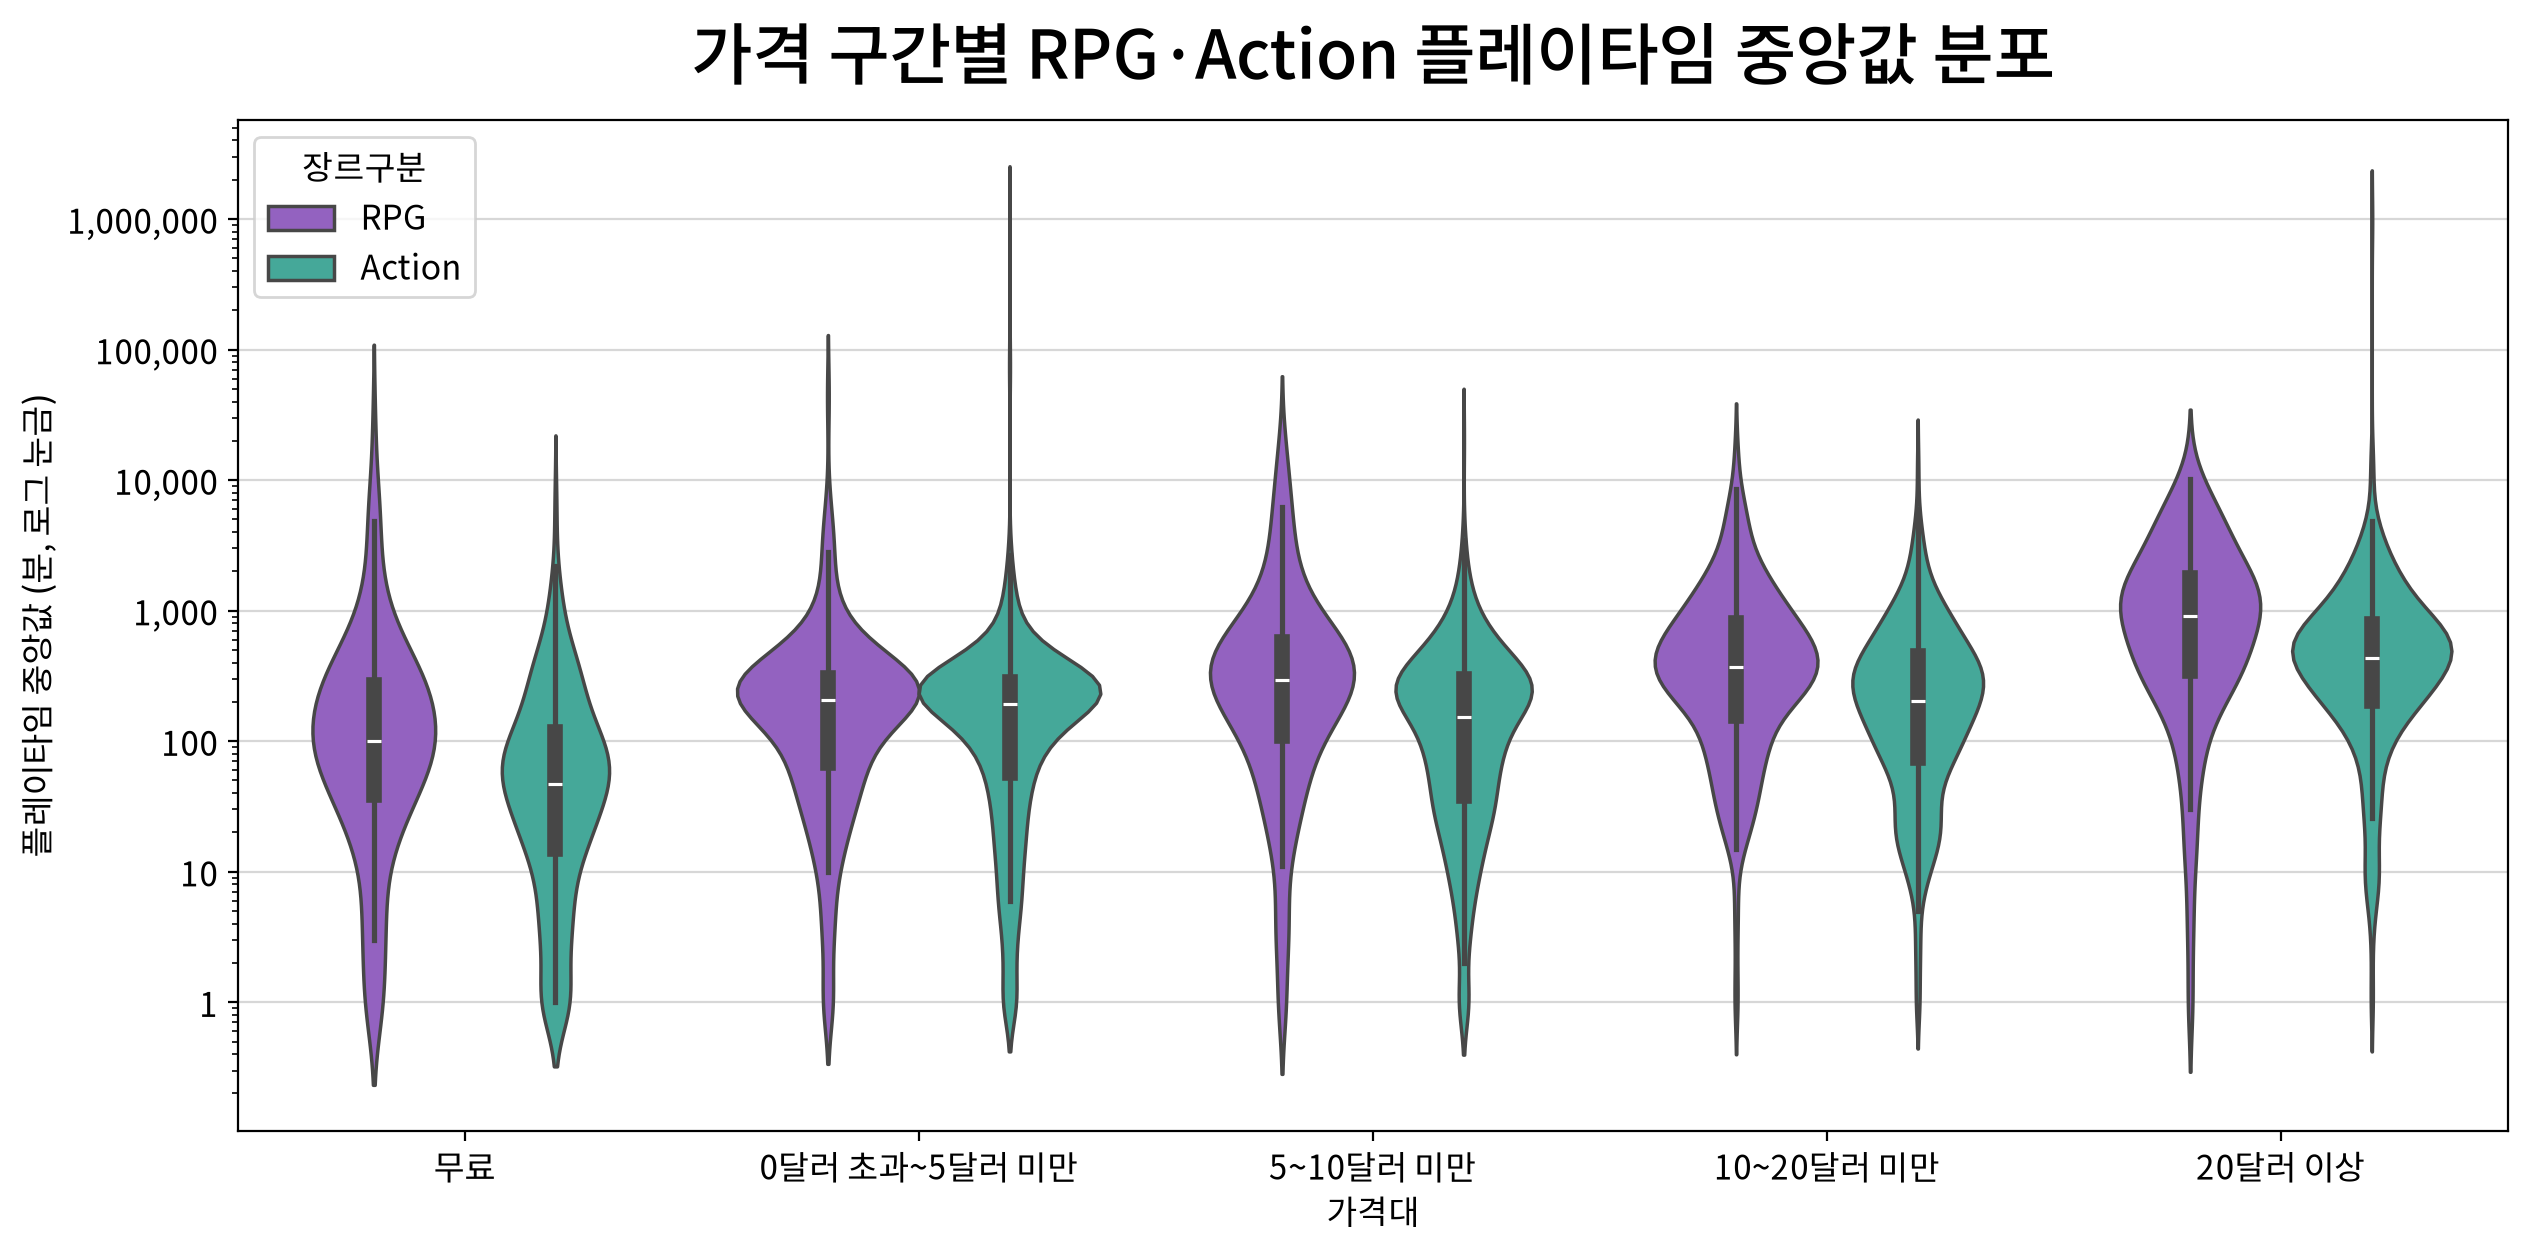

In [32]:
# 바이올린 플롯 그리기
# RA['log_playtime'] = np.log1p(RA['median_playtime'])
# my_plot.violinplot(RA, x='가격대', y='log_playtime', hue='장르구분', order=order,
#                   palette= {'RPG': '#9452D0', 'Action': '#35B8A5'},
#                   title="RPG와 Action의 가격대별 플레이타임 분포 비교",
#                   ylabel='median_playtime(분)')

import matplotlib.ticker as ticker

# 플레이타임이 양수인 데이터
plot_data = RA[RA['median_playtime'] > 0]

# 그래프 생성
fig, ax = my_plot.init(title='가격 구간별 RPG·Action 플레이타임 중앙값 분포')

# Y축 로그 눈금 설정
ax.set_yscale('log')

# 바이올린 플롯
my_plot.violinplot(
    plot_data,
    x='가격대',
    y='median_playtime',
    hue='장르구분',
    order=order,
    ax=ax,
    palette= {'RPG': '#9452D0', 'Action': '#35B8A5'}
)

# Y축을 실제 분 단위로 표시
ax.yaxis.set_major_locator(ticker.LogLocator(base=10))
ax.yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda y, pos: f'{y:,.0f}' if y >= 1 else '')
)

ax.set_xlabel('가격대')
ax.set_ylabel('플레이타임 중앙값 (분, 로그 눈금)')

my_plot.show()

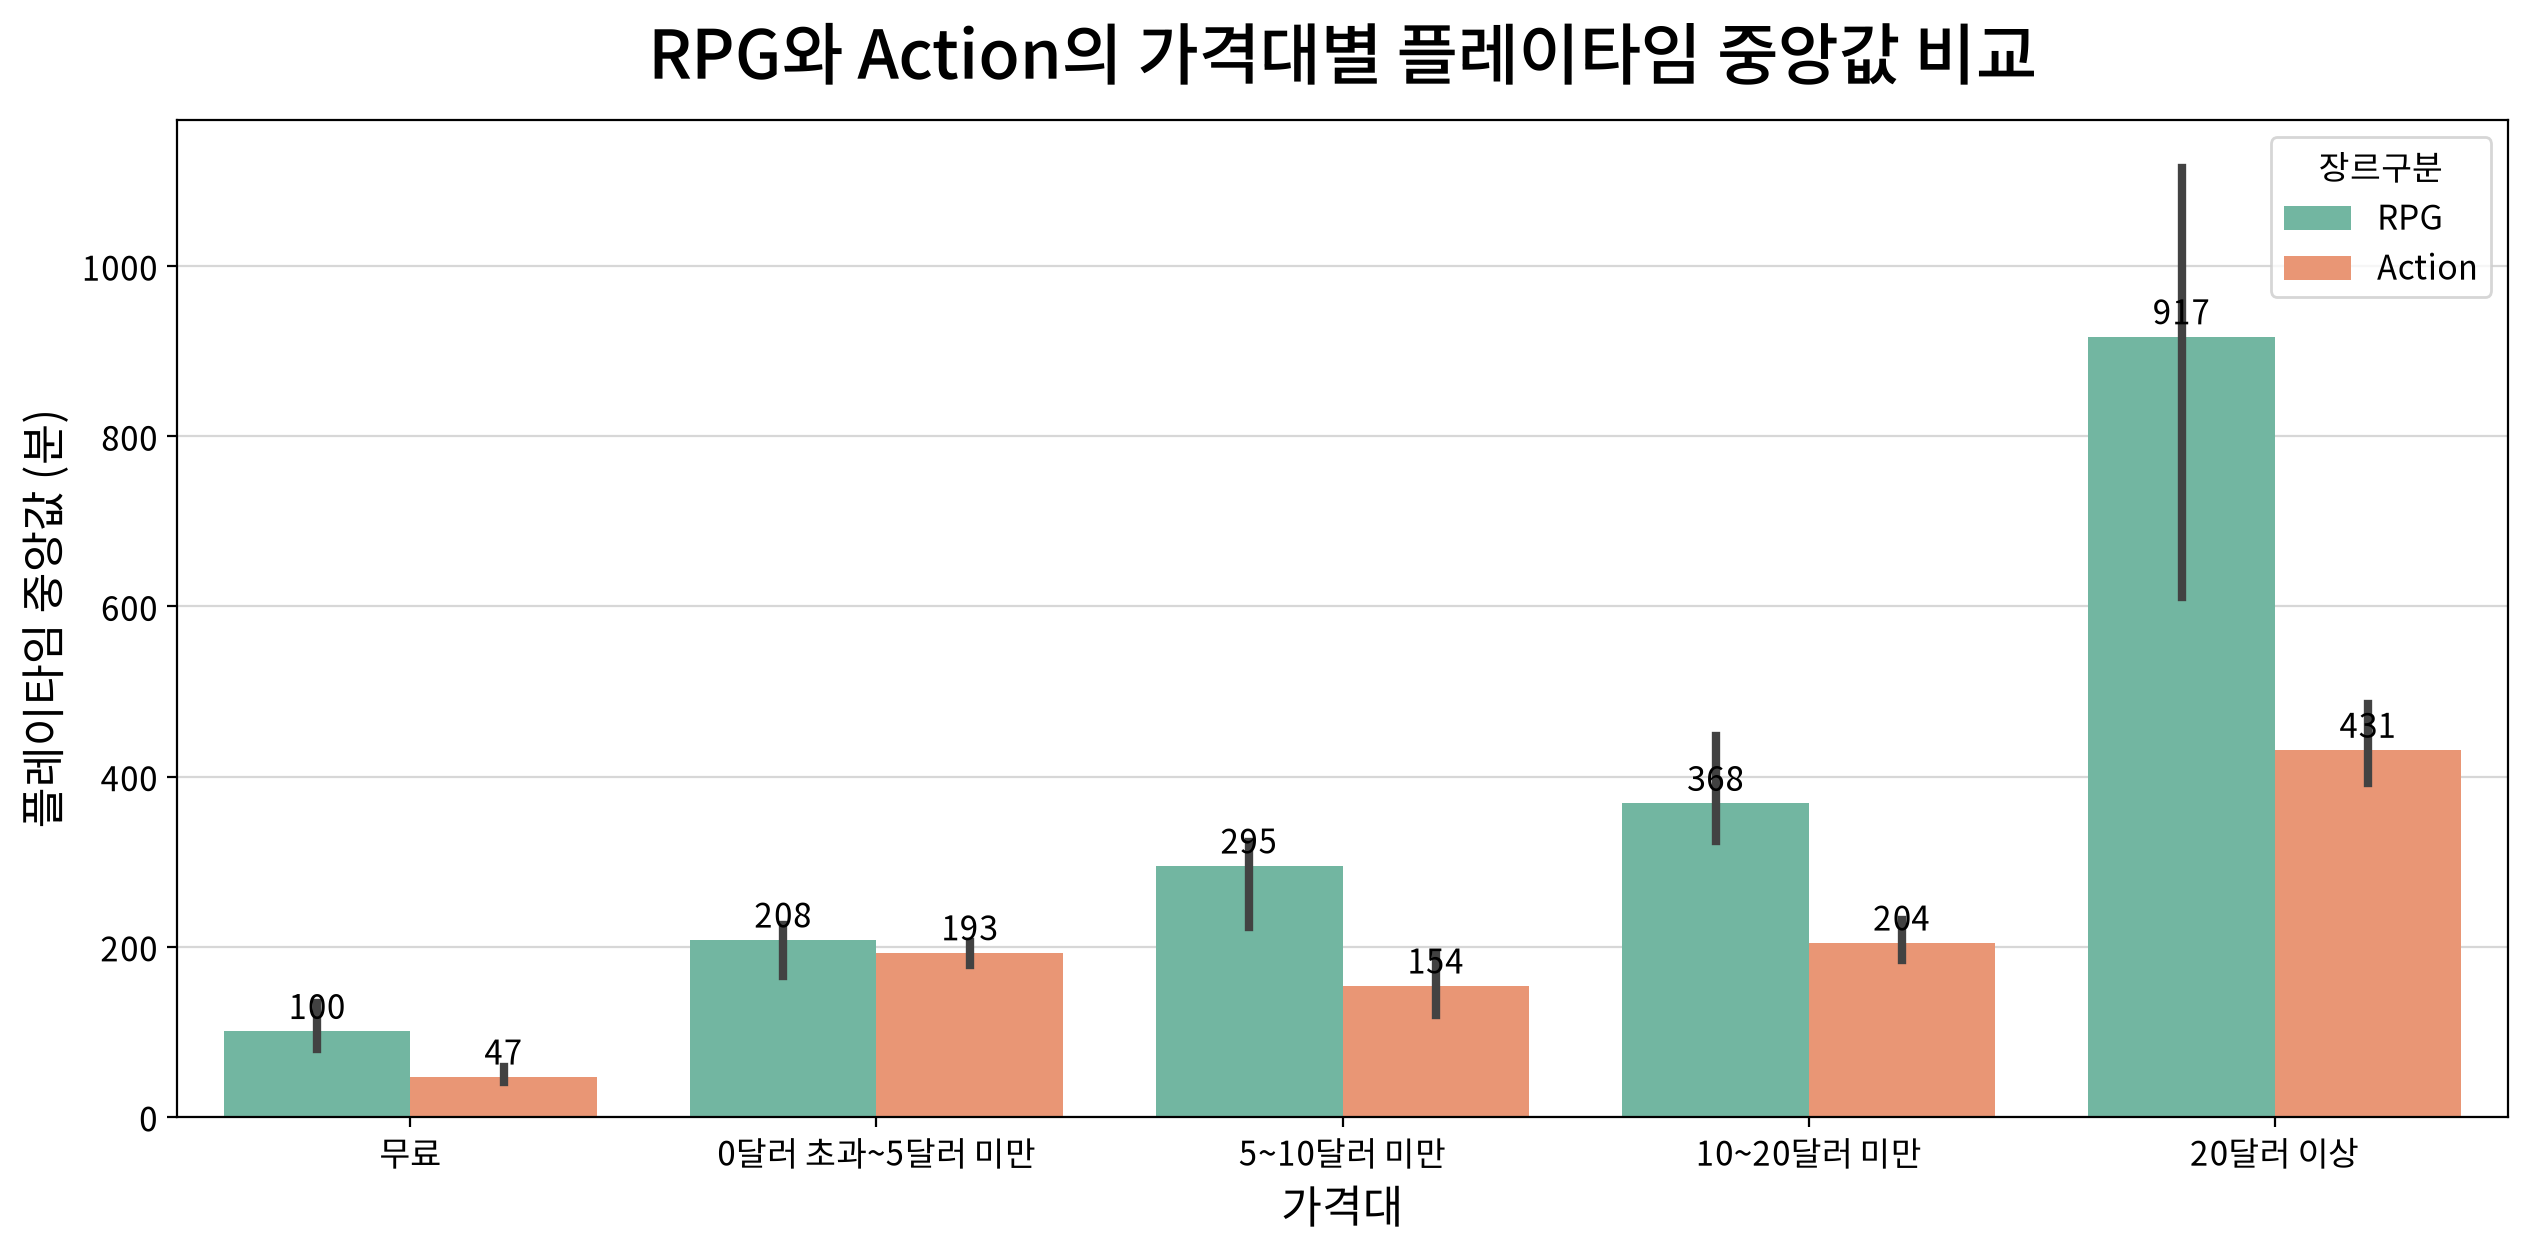

In [15]:
# RPG 와 Action장르 게임의 플레이타임 중앙값 비교 그래프

my_plot.barplot(data=RA, x='가격대', y='median_playtime',
                hue='장르구분',estimator=np.median,
                order=order,
                palette='Set2', title='RPG와 Action의 가격대별 플레이타임 중앙값 비교',
                xlabel='가격대', ylabel='플레이타임 중앙값 (분)', text=True)

> **1. 0달러 초과~ 5달러 미만의 가격대 구간을 제외하고 `RPG`와 `Action`의 플레이타임 중앙값에 격차가 존재** 
> - 0달러 초과~5달러 미만을 뺀 4개 구간에서의 `RPG`의 플레이타임 중앙값이 높다.
> - 특히 20달러 이상 구간에서 두 장르에 동시에 속한 게임 817개를 제외한 결과, RPG의 플레이타임 중앙값은 917분, Action은 431분으로 나타났다. 두 장르의 차이는 486분이며, RPG가 Action보다 약 2.13배 높았다.
> - `RPG` 장르의 **바이올린 플롯**에서도 20달러 이상 구간의 플레이타임 분포가 소수의 극단값에만 집중되지 않고, 비교적 높은 플레이타임 구간에 형성되어 있음을 확인할 수 있다.
> - 이는 해당 가격대에서 `RPG` 장르의 플레이타임 중앙값이 높게 나타난 결과가 단순히 일부 극단값에 의한 현상은 아니라는 해석을 뒷받침한다.
> 
> **2. `RPG`와 `Action`의 가격대별 변화 패턴 차이**
> - `RPG`는 가격대가 높아질수록 플레이타임 중앙값이 일관되게 증가하는 경향을 보였다.
> - 반면 `Action`은 5~10달러 미만 구간에서 154분으로, 직전 가격 구간의 193분보다 39분 감소하는 예외적인 패턴을 보였다.
> - 이러한 차이는 가격대와 플레이타임 중앙값의 관계가 장르별로 다르게 나타날 수 있음을 시사하며, 출시연도나 콘텐츠 규모 등 다른 요인의 영향도 함께 고려해야 한다.

#### Q2-2. DLC 유무에 따라 가격대별 플레이타임 차이가 나타나는가?

가격대 × DLC 유무별 플레이타임의 기술통계량을 확인한다.

In [16]:
origin.groupby(['가격대', 'DLC'])['median_playtime'].agg(
    count='count',
    median='median',
    iqr=lambda x: x.quantile(.75) - x.quantile(.25)
).round(2).reindex(order, level='가격대')

count  median      iqr
가격대           DLC                        
무료            없음     711    41.0   134.00
              있음     329    78.0   174.00
0달러 초과~5달러 미만 없음    1605   192.0   238.00
              있음     636   189.0   242.00
5~10달러 미만     없음     920   163.5   295.50
              있음     602   244.5   358.25
10~20달러 미만    없음     992   235.0   457.75
              있음    1089   302.0   515.00
20달러 이상       없음     388   401.5   837.75
              있음     738   588.5  1002.00

가격대 구간별로 DLC 유무에 따른 게임 수의 비중을 확인한다. 

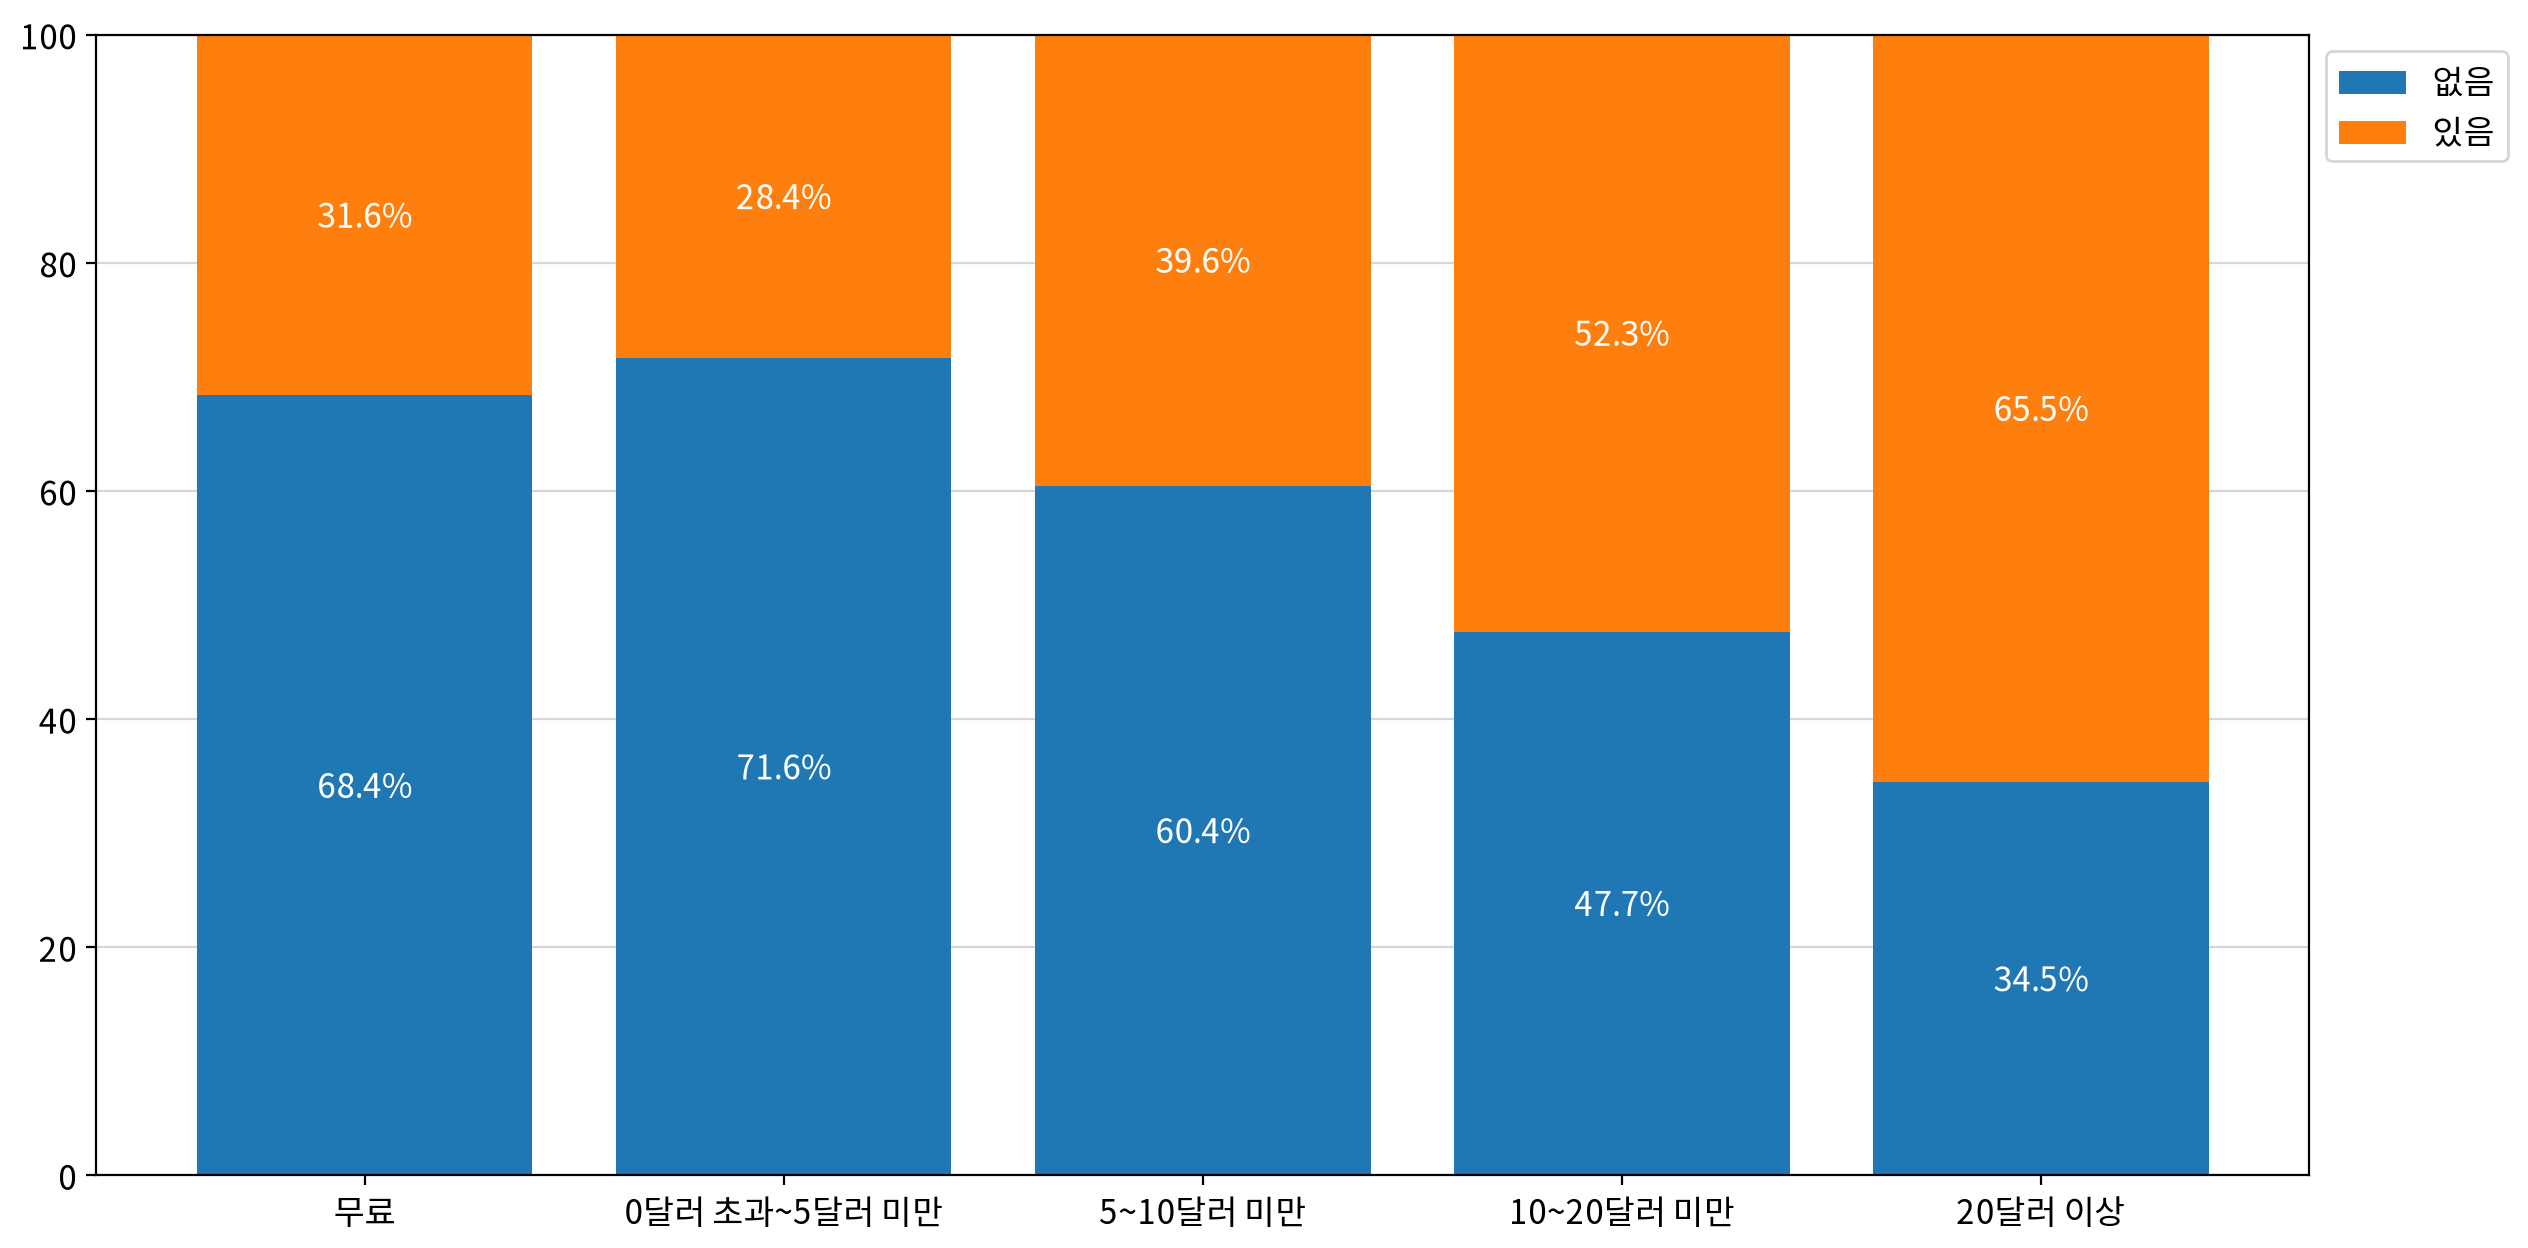

In [17]:
# 누적 막대그래프 그리기
my_plot.stackplot(origin.assign(게임수=1), x='가격대', y='게임수', hue='DLC', order=order, ratio=True)

> DLC 유무에 따른 가격대별 플레이타임 차이를 비교하기 위해 그룹형 막대그래프를 활용하고자 한다.

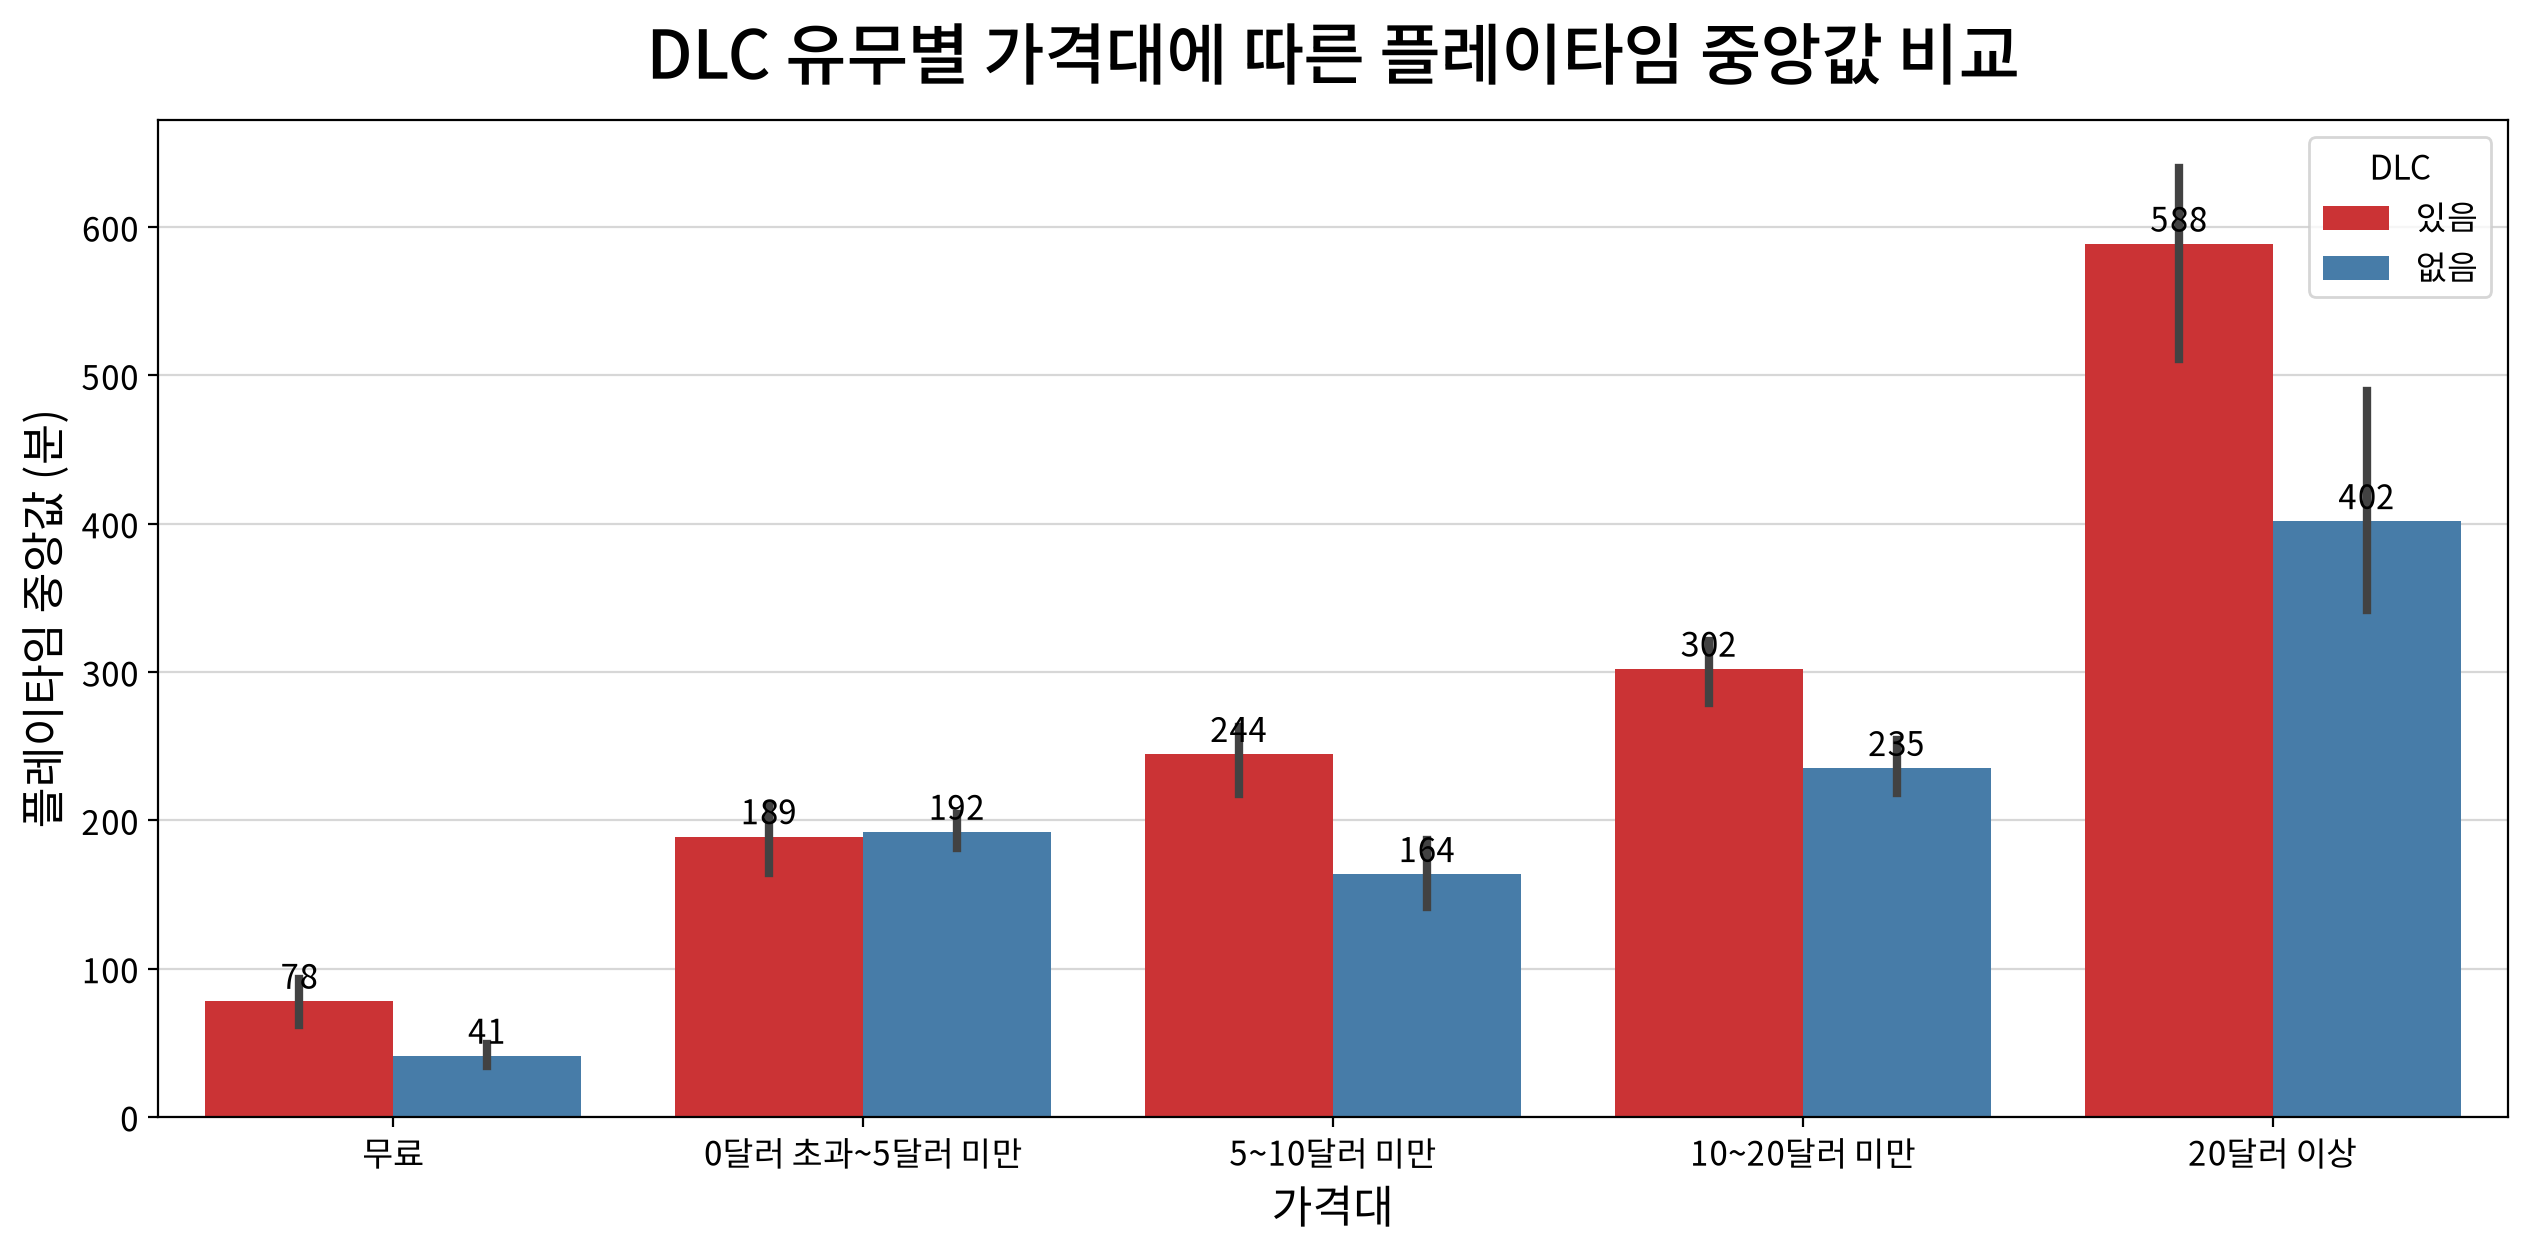

In [18]:
# barplot 그리기
my_plot.barplot(data=origin, x='가격대', y='median_playtime',
                hue='DLC',  estimator=np.median,
                order=order,
                palette='Set1', title='DLC 유무별 가격대에 따른 플레이타임 중앙값 비교',
                xlabel='가격대', ylabel='플레이타임 중앙값 (분)', text=True)

> **1. 가격대 상승에 따른 플레이타임 중앙값 우상향**
> - `무료` 게임부터 `20달러 이상` 고가 게임으로 갈수록 플레이타임 중앙값이 대체로 증가하는 경향을 보인다.
> - 특히 20달러 이상 구간에서 두 장르에 동시에 속한 게임 817개를 제외한 결과, RPG의 플레이타임 중앙값은 917분, Action은 431분으로 나타났다. 두 장르의 차이는 486분이며, RPG가 Action보다 약 2.13배 높았다.> 
>
> **2. DLC 유무에 따른 플레이타임 중앙값 차이**
> - `0달러 초과~5달러 미만` 구간을 제외한 모든 가격대에서 DLC가 있는 게임의 플레이타임 중앙값이 DLC가 없는 게임보다 높게 나타났다.
> - 가격대별 DLC 유무에 따른 표본 구성에도 차이가 나타났다. 무료 게임에서는 DLC가 없는 게임이 711개로 더 많았으나, 20달러 이상 구간에서는 DLC가 있는 게임이 738개로 더 많았다.
> - 따라서 가격대별 DLC 유무에 따른 플레이타임 중앙값 차이를 해석할 때 표본 구성의 차이도 함께 고려할 필요가 있다.
> - 이러한 결과는 DLC 유무와 플레이타임 중앙값 사이에 연관성이 있음을 시사하지만, DLC가 플레이타임을 직접 증가시킨다고 단정할 수는 없다.
> 
> **3. `0달러 초과~5달러 미만` 구간에서의 예외 패턴**
> - `0달러 초과~5달러 미만` 구간에서는 DLC가 있는 게임과 없는 게임의 플레이타임 중앙값이 각각 189분과 192분으로 거의 유사하게 나타났다.
> - 이러한 차이는 다른 가격대에서 관찰된 패턴과 구분되며, 추가적인 게임 특성을 고려한 분석이 필요하다.

#### Q2-3. 도전과제 구간에 따라 가격대별 플레이타임 차이가 나타나는가?

가격대 × 도전과제 구간별 플레이타임의 기술통계량을 확인한다.

In [19]:
origin.groupby(['가격대', '도전과제'])['median_playtime'].agg(
    count='count',
    median='median',
    iqr=lambda x: x.quantile(.75) - x.quantile(.25)
).round(2).reindex(order, level='가격대')

count  median      iqr
가격대           도전과제                          
무료            0개        494    37.0   110.75
              1~20개     224    46.0   106.25
              21~40개    125    74.0   231.00
              41개 이상    197   109.0   279.00
0달러 초과~5달러 미만 0개        636   195.0   259.25
              1~20개     819   181.0   214.50
              21~40개    449   209.0   231.00
              41개 이상    337   193.0   277.00
5~10달러 미만     0개        355   131.0   275.00
              1~20개     483   178.0   273.00
              21~40개    382   203.0   295.50
              41개 이상    302   267.0   514.50
10~20달러 미만    0개        346   255.5   542.25
              1~20개     437   181.0   303.00
              21~40개    690   250.5   497.50
              41개 이상    608   367.5   626.50
20달러 이상       0개        131   444.0  1231.50
              1~20개     107   335.0   600.00
              21~40개    316   440.5   682.75
              41개 이상    572   663.0  1093.00

> 가격대 구간별로 도전과제 개수에 따른 게임 수의 비중을 확인한다.

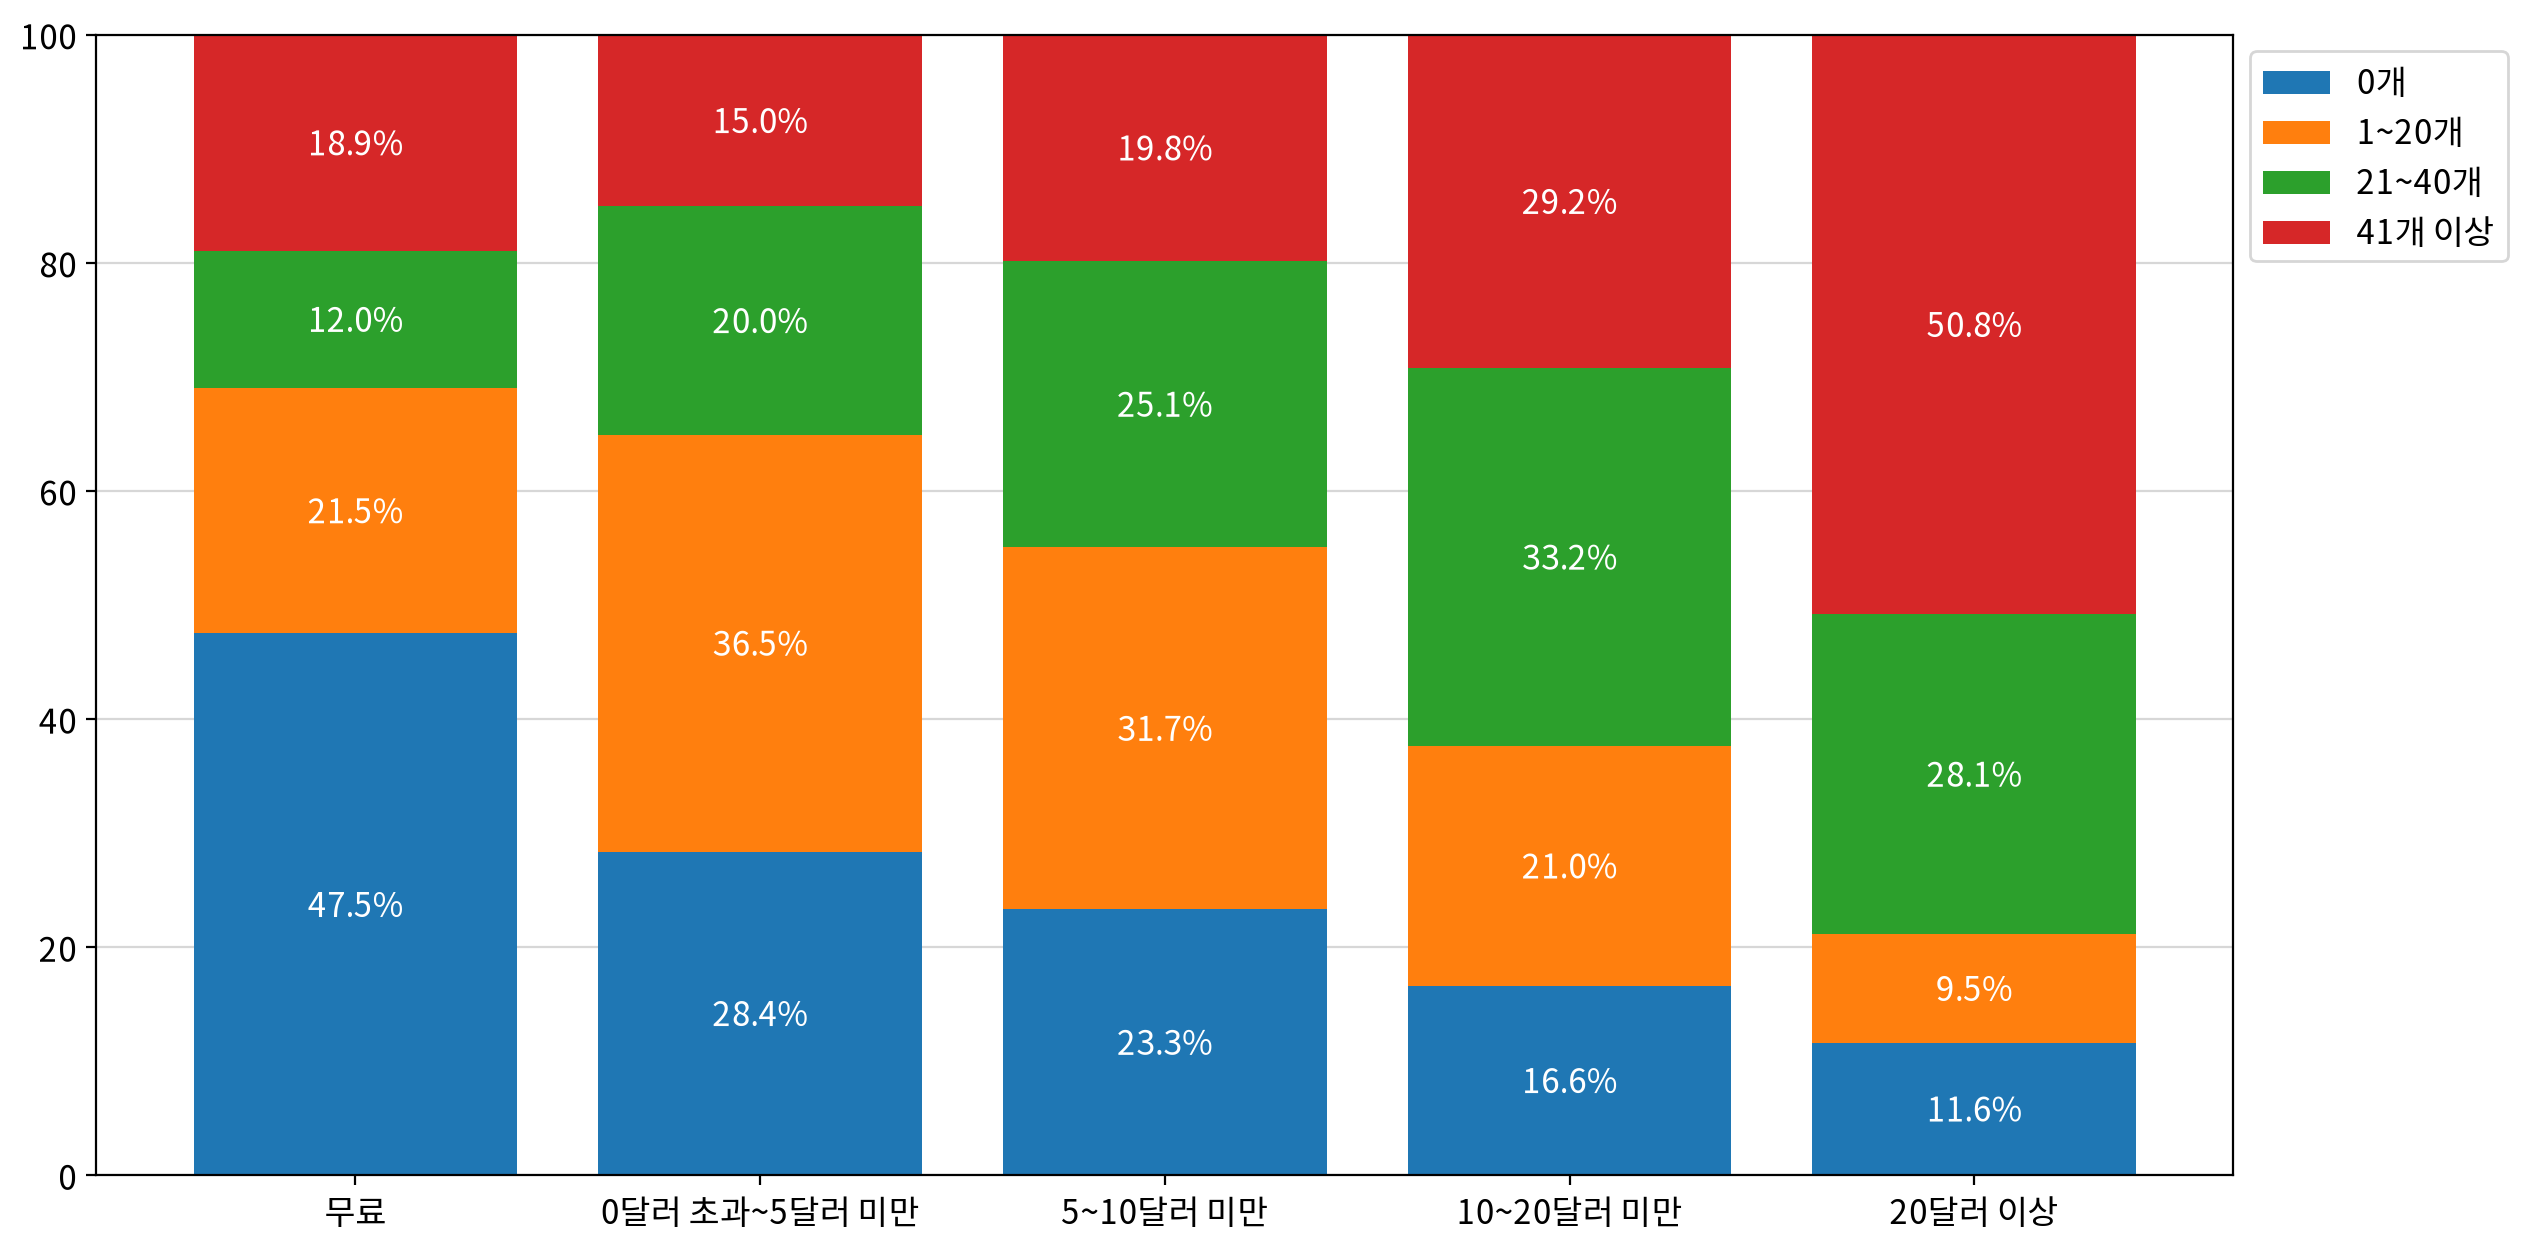

In [20]:
# 누적 막대그래프 그리기
my_plot.stackplot(origin.assign(게임수=1), x='가격대', y='게임수', hue='도전과제', order=order, palette="tab10", ratio=True)

> 도전과제 수에 따른 가격대별 플레이타임의 변화 양상을 비교하기 위해, 라인 플롯을 활용해 도전과제 수에 따라 가격대별 플레이타임 중앙값 사이의 관계가 서로 다르게 나타나는지 탐색하고자 한다.

In [21]:
# 도전과제의 개수 구간으로 그룹화하고 플레이타임 중앙값 컬럼의 중앙값 집계
df2 = pivot_table(origin, index="도전과제", columns="가격대", values="median_playtime", aggfunc='median')

df_median = df2.reindex(columns=order)
df_median

가격대,무료,0달러 초과~5달러 미만,5~10달러 미만,10~20달러 미만,20달러 이상
도전과제,,,,,
0개,37.0,195.0,131.0,255.5,444.0
1~20개,46.0,181.0,178.0,181.0,335.0
21~40개,74.0,209.0,203.0,250.5,440.5
41개 이상,109.0,193.0,267.0,367.5,663.0


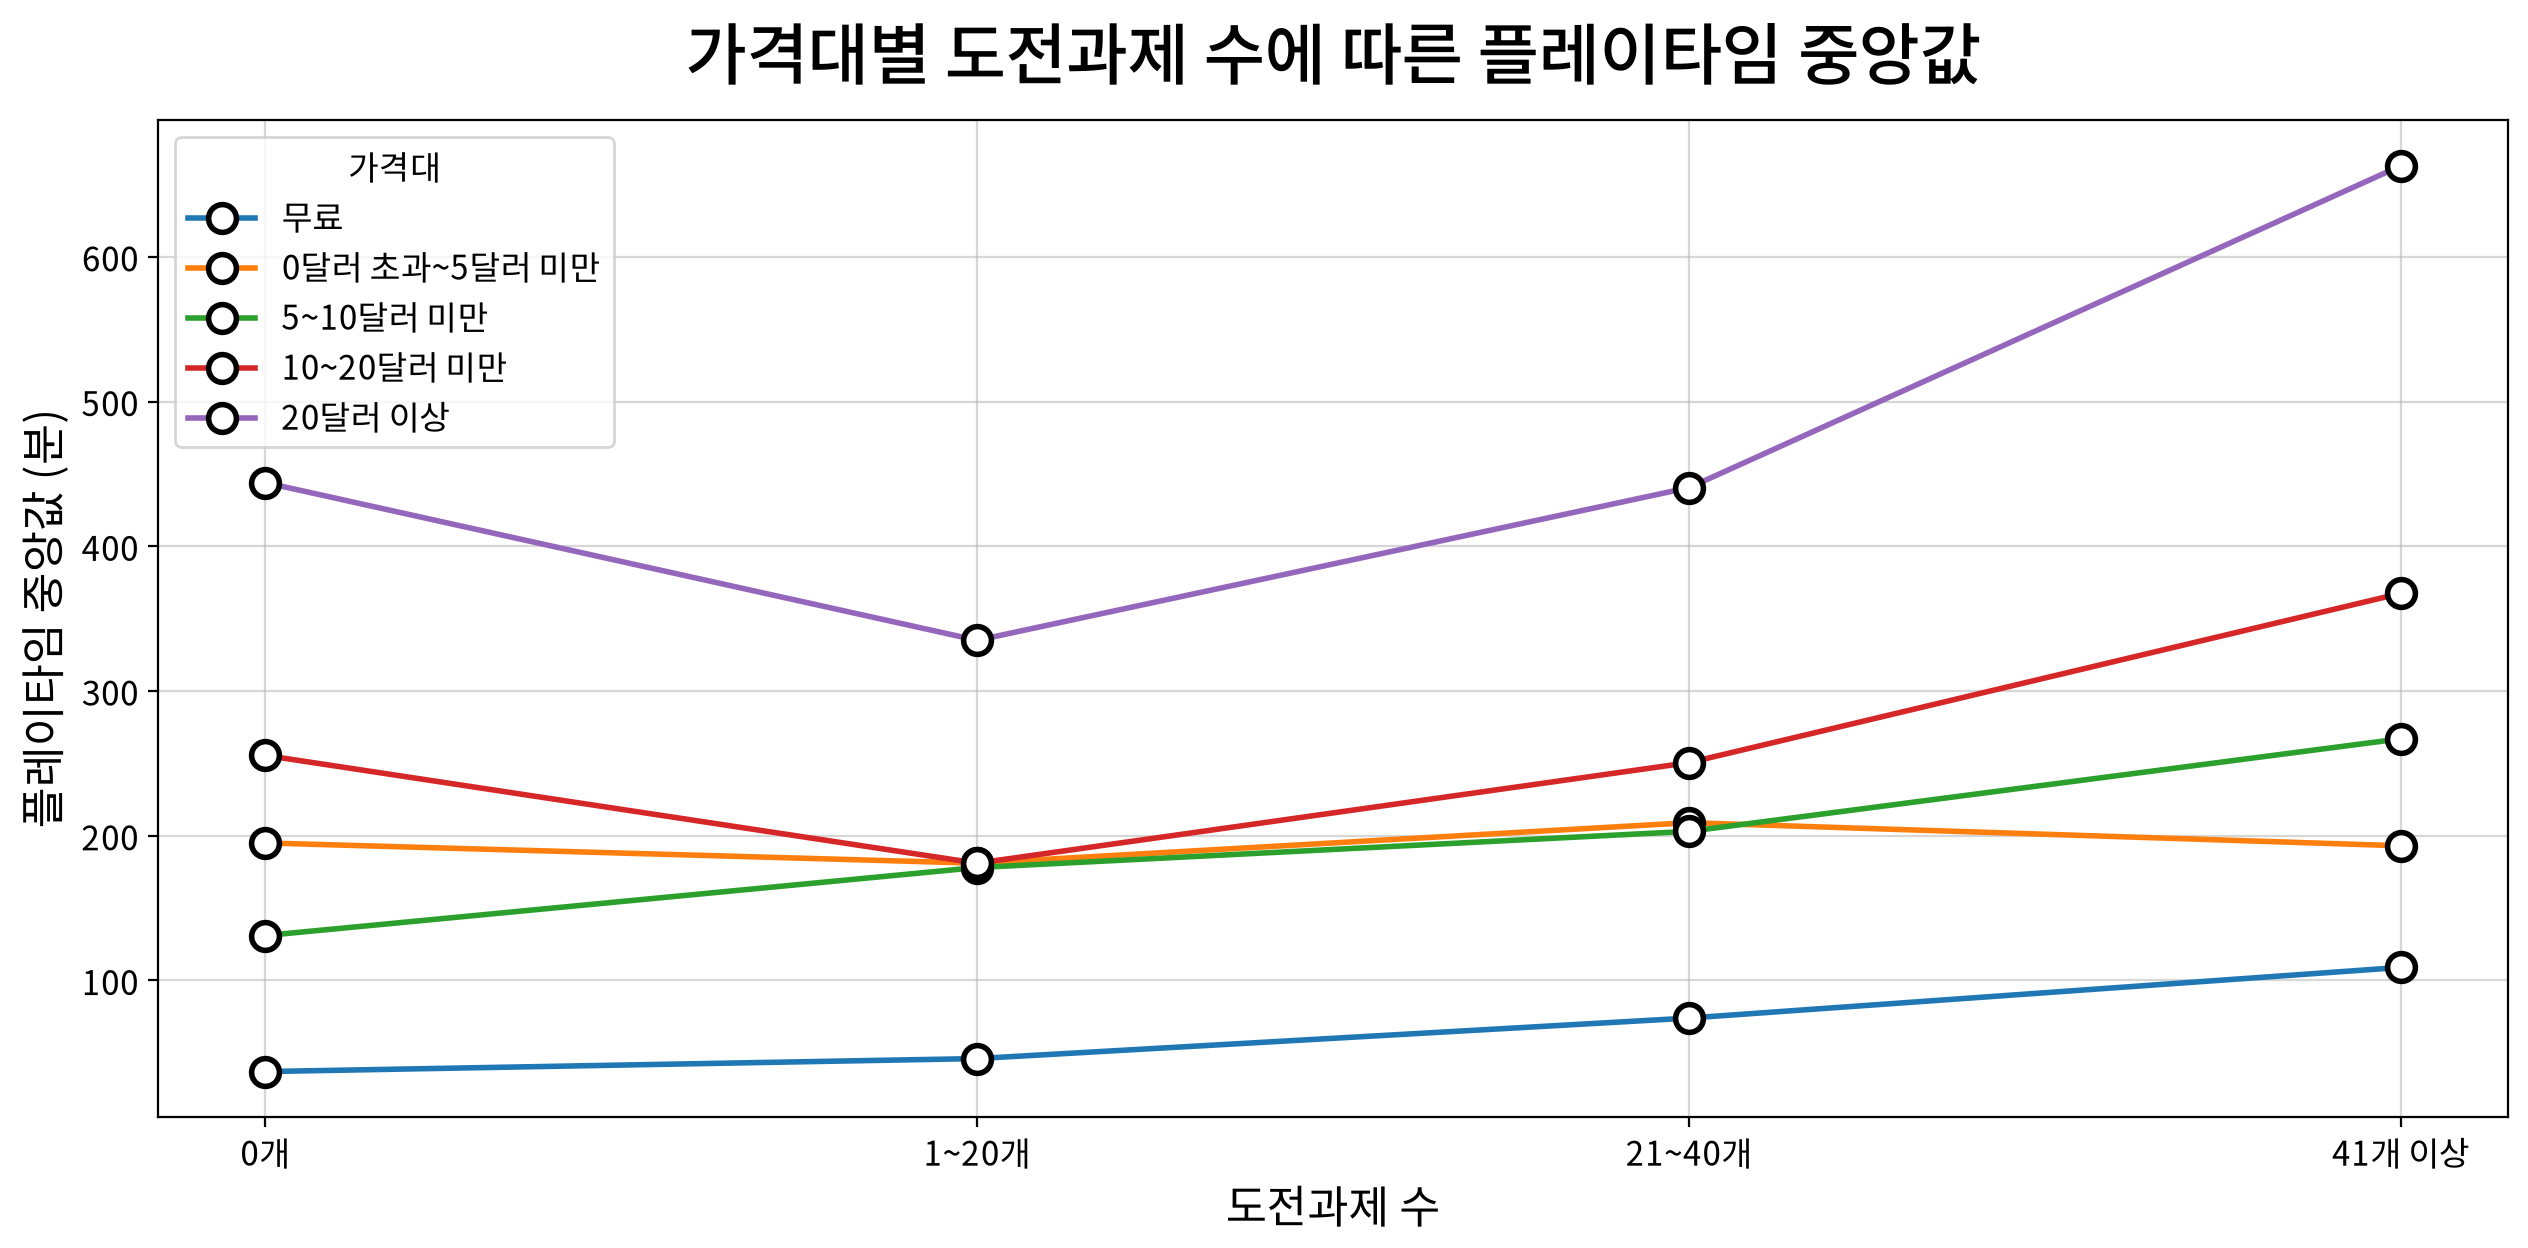

In [22]:
# 라인 그래프 출력 준비
df3 = pd.melt(
    df_median.reset_index(),
    id_vars='도전과제',
    var_name='가격대',
    value_name='플레이타임'
)

# 라인 그래프 출력
my_plot.lineplot(data=df3,
                x='도전과제',
                y="플레이타임", 
                hue="가격대", 
                title="가격대별 도전과제 수에 따른 플레이타임 중앙값", 
                xlabel="도전과제 수", ylabel="플레이타임 중앙값 (분)", 
                marker="o", 
                markersize=10, 
                markeredgewidth=2, 
                markeredgecolor="#000000", 
                markerfacecolor="#ffffff"
                )

> **1. 가격대별 도전과제 개수 분포의 차이**
> - 20달러 이상 게임에서는 도전과제가 41개 이상인 비중이 50.8%로 절반 이상을 차지한 반면, 무료 게임에서는 0개인 비중이 47.5%로 가장 높았다.
>
> **2. 무료·5~10달러 미만에서만 도전과제가 많을수록 증가**
> - 도전과제가 `41개 이상`인 게임은 대부분의 가격대에서 상대적으로 높은 플레이타임 중앙값을 기록하였다.
> - 그러나 일부 가격대에서는 도전과제가 `0개`인 게임보다 `1~20개`인 게임의 플레이타임 중앙값이 낮게 나타나, 도전과제 개수와 플레이타임 사이에 일관된 증가 관계가 있다고 단정하기는 어렵다.
> 
> **3. 가격대에 따른 도전과제 개수와 플레이타임 중앙값의 관계**
> - 동일한 가격대에서 도전과제 개수에 따른 플레이타임 중앙값을 비교한 결과, 가격대에 따라 서로 다른 양상이 나타났다.
> - 무료와 5~10달러 미만 구간에서는 도전과제 개수가 많을수록 플레이타임 중앙값이 일관되게 증가하였다.
> - 도전과제 `41개 이상` 게임은 5개 가격대 중 4개 구간에서 가장 높은 플레이타임 중앙값을 기록하였다.
> - 반면 0달러 초과~5달러 미만, 10~20달러 미만, 20달러 이상 구간에서는 도전과제가 `0개`인 게임보다 `1~20개`인 게임의 중앙값이 낮게 나타나는 등 예외적인 패턴이 관찰되었다.
> - 따라서 도전과제 개수가 많은 게임에서 플레이타임 중앙값이 상대적으로 높은 경향은 관찰되었으나, 모든 가격대에서 일관된 증가 관계가 나타난 것은 아니다.
>
> **4. 선행연구**
> - Rizani et al.(2023)은 Steam 게임 18,658개를 분석하여 도전과제 개수가 매우 많지만 가격이 낮고, 짧은 시간에 다수의 도전과제를 획득할 수 있는 게임 집단(Achievement Spam Games)을 발견하였다.
> - Cunha et al.(2024)의 연구에 따르면 Steam 게임의 약 75%가 도전과제 40개 이하에 해당하며, 도전과제 개수가 많다고 반드시 게임의 난이도가 높거나 플레이에 더 많은 시간이 소요되는 것은 아니라는 것을 보여준다.
> - 이러한 선행연구는 도전과제 수와 플레이타임이 반드시 비례하지는 않음을 시사한다.
> - 따라서 도전과제 개수가 반드시 긴 플레이타임을 의미하는 것은 아니며, 본 분석의 예외 현상 역시 도전과제의 달성 난이도와 게임 설계 방식 등 다른 요인과 관련되어 있을 가능성이 있다.

### #02 분석 결과 및 결론

#### 1. 분석 결과

> - Q1. 어느 가격대의 게임에서 플레이타임이 가장 길게 나타나는가?
>   - **20달러 이상(522.5분)이 가장 길다**.
>   - 무료 게임의 플레이타임 중앙값은 51분, 20달러 이상 게임은 522.5분으로 약 10.25배의 차이가 나타났다.
>   - 다만 모든 가격 구간에서 플레이타임 중앙값이 일정한 비율로 증가하지는 않았다.
>
> - Q2-1. 가격대에 따라 장르별 플레이타임 중앙값 차이가 있는가?
>   - **동일한 가격대에서도 장르에 따라 플레이타임 중앙값에 차이가 나타났다.**
>   - 특히 RPG는 0달러 초과~5달러 미만을 제외한 4개 가격대에서 Action보다 높은 플레이타임 중앙값을 보였으며, 20달러 이상 구간에서 두 장르 간 차이가 가장 크게 나타났다.
>   - 따라서 가격대뿐 아니라 게임 장르도 플레이타임 중앙값 차이를 이해하는 데 고려할 필요가 있다.
>
> - Q2-2. DLC 유무에 따라 가격대별 플레이타임 중앙값 차이가 나타나는가?
>   - **무료, 5~10달러 미만, 10~20달러 미만, 20달러 이상 구간에서는 DLC가 있는 게임의 플레이타임 중앙값이 더 높게 나타났다.**
>   - 반면 0달러 초과~5달러 미만 구간에서는 DLC가 없는 게임의 중앙값이 소폭 높았다.
>   - 따라서 DLC 유무에 따른 플레이타임 중앙값 차이는 가격대에 따라 다르게 나타났다.
>
> - Q2-3. 도전과제 구간에 따라 가격대별 플레이타임 차이가 나타나는가?
>   - **동일한 가격대에서도 도전과제 개수에 따라 플레이타임 중앙값에 차이가 나타났다.**
>   - 무료와 5~10달러 미만 구간에서는 도전과제 개수가 많을수록 플레이타임 중앙값이 일관되게 증가하였다.
>   - 도전과제 41개 이상 게임은 5개 가격대 중 4개 구간에서 가장 높은 플레이타임 중앙값을 기록하였다.
>   - 다만 나머지 가격대에서는 도전과제 개수가 증가해도 플레이타임 중앙값이 감소하는 등 일관되지 않은 양상이 나타났다.

> - 예상①: 20달러 이상 가격대의 플레이타임 중앙값은 5~10달러 미만 가격대보다 높지 않을 것이다.
>   - 분석 결과, 20달러 이상 게임의 플레이타임 중앙값은 522.5분으로, 5~10달러 미만 게임의 197분보다 약 2.65배 높게 나타났다.
>   - 따라서 사전 예상과 달리 20달러 이상 가격대에서 더 높은 플레이타임 중앙값이 관찰되었다.
>
> - 예상②: 동일한 가격대에서 RPG와 Action 장르 게임의 플레이타임 중앙값은 차이가 없을 것이다.
>   - 0달러 초과~5달러 미만을 뺀 4개 구간에서 예상과 달랐다.
>   - 20달러 이상 구간에서 두 장르 간 플레이타임 중앙값 차이가 가장 크게 나타났다.
>   - 다만 본 분석은 기술통계량 비교를 중심으로 수행하였으므로, 관찰된 차이의 통계적 유의성은 검증하지 않았다.

#### 2. 결론 및 한계

##### 1. 주요 결론

> **① 게임 가격대가 높을수록 플레이타임 중앙값이 증가하는 경향이 관찰되었다.**

- 플레이타임 중앙값이 양수인 Steam 인기 게임 8,010개를 분석한 결과, 무료 게임의 플레이타임 중앙값은 51분, 20달러 이상 게임은 522.5분으로 약 10.25배의 차이가 나타났다.
- 장르별 분석과 도전과제 개수별 분석에서도 20달러 이상 게임이 무료 게임보다 높은 플레이타임 중앙값을 보이는 공통적인 경향이 확인되었다.
- 다만 모든 가격 구간에서 플레이타임 중앙값이 비례적으로 증가하는 것은 아니었다.

> **② DLC와 도전과제 역시 플레이타임과 관련된 게임 특성으로 나타났다.**

- DLC 유무별 분석에서는 일부 저가 구간을 제외한 대부분의 가격대에서 DLC가 있는 게임의 플레이타임 중앙값이 더 높게 나타났다.
- 도전과제 분석에서는 41개 이상의 도전과제를 보유한 게임이 5개 가격대 중 4개 구간에서 가장 높은 플레이타임 중앙값을 기록하였다.
- 다만 도전과제 개수가 많을수록 플레이타임 중앙값이 일관되게 증가하는 관계는 무료와 5~10달러 미만 구간에서만 나타났다.
- 따라서 도전과제 개수가 많은 게임에서 상대적으로 높은 플레이타임 중앙값이 관찰되었으나, 이러한 관계가 모든 가격대에서 동일하게 나타나는 것은 아니었다.

> **③ 동일한 가격대에서도 장르와 게임 특성에 따라 플레이타임 차이가 나타났다.**

- 장르별 분석에서는 0달러 초과~5달러 미만을 뺀 4개 구간에서 RPG의 플레이타임 중앙값이 Action보다 높게 나타났으며, 특히 20달러 이상 구간에서 두 장르의 차이가 가장 컸다.
- 도전과제 개수와 플레이타임의 관계 역시 가격대에 따라 서로 다른 양상을 보였으며, 일부 구간에서는 도전과제가 많아도 플레이타임 중앙값이 낮게 나타났다.
- 이러한 결과는 플레이타임의 차이를 이해하기 위해 가격대뿐 아니라 장르, DLC, 도전과제 등 여러 게임 특성을 함께 고려할 필요가 있음을 시사한다.

##### 2. 분석의 한계

> **① 변수별 기술통계 분석의 한계**

- 가격대·장르·DLC 유무·도전과제 구간별 분석에서 전반적으로 IQR이 크게 나타나, 동일한 집단에 속한 게임 간에도 플레이타임 중앙값의 차이가 컸다.
- 따라서 집단별 중앙값만으로 개별 게임의 플레이타임을 충분히 설명하기에는 한계가 있으며, IQR과 변수별 게임 수를 함께 고려하여 해석할 필요가 있다.

> **② 탐색적 분석에 따른 해석의 한계**

- 본 분석은 게임 특성에 따른 플레이타임 중앙값을 비교한 탐색적 분석으로, 다른 변수의 영향을 통제하거나 개별 변수의 독립적인 영향력을 검증하지는 않았다.
- 따라서 가격대, 장르, DLC, 도전과제 등이 플레이타임과 복합적으로 관련되어 있을 가능성은 있으나, 개별 변수의 영향을 단정하기는 어렵다.
- 이러한 관계를 보다 구체적으로 확인하기 위해서는 다중회귀분석 등 추가적인 분석이 필요하다.

> **③ 데이터 및 전처리 과정의 한계**

- 플레이타임 중앙값이 양수인 게임만 분석 대상으로 선정하였으므로, 표본 선택 편향이 발생했을 가능성이 있다.
- 또한 장르 중복 집계, 극단값 및 출시 경과 기간의 미반영 등이 분석 결과에 영향을 미쳤을 가능성이 있다.
- 따라서 본 분석 결과를 전체 Steam 게임으로 일반화하는 데에는 주의가 필요하다.

> ##### 참고문헌
>
> Bailey, E. N. (2020). Video game business management economics: Employing industry-level data to improve the decision-making process [Doctoral dissertation, Japan Advanced Institute of Science and Technology].
>
> Cunha, L. R., Mendes, L. O., & Mendes, R. S. (2024). Complexity of popularity and dynamics of within-game achievements in computer games. arXiv:2404.15295. https://arxiv.org/abs/2404.15295
>
> Ebbing, T., & Lüthje, C. (2021). Pricing decisions of consumer innovators. Research Policy, 50(8), Article 104169. https://doi.org/10.1016/j.respol.2020.104169   
>
> Guzsvinecz, T., & Szűcs, J. (2023). Length and sentiment analysis of reviews about top-level video game genres on the Steam platform. Computers in Human Behavior, 149, 107955. https://doi.org/10.1016/j.chb.2023.107955
>
> Rizani, M. N., Khalid, M. N. A., & Iida, H. (2023). Application of meta-gaming concept to the publishing platform: Analysis of the Steam games platform. Information, 14(2), 110. https://doi.org/10.3390/info14020110